# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Evaluation Settings

## 15-minutes granularity

In [4]:
DATA_FREQUENCY = '15min'
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 9  # Prominence for spike detection, adjusted after EDA

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_15m_new_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
            'L1_act_power_lag_15min', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 
            'L1_app_power_lag_15min', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
            'L1_current_lag_15min', 'L1_current_lag_1h', 'L1_current_lag_24h', 
            'L1_react_power_lag_15min', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
            'L1_voltage_lag_15min', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
            'L2_act_power_lag_15min', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 
            'L2_app_power_lag_15min', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
            'L2_current_lag_15min', 'L2_current_lag_1h', 'L2_current_lag_24h', 
            'L2_react_power_lag_15min', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
            'L2_voltage_lag_15min', 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
            'L3_act_power_lag_15min', 'L3_act_power_lag_1h', 'L3_act_power_lag_24h',
            'L3_app_power_lag_15min', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
            'L3_current_lag_15min', 'L3_current_lag_1h', 'L3_current_lag_24h', 
            'L3_react_power_lag_15min', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
            'L3_voltage_lag_15min', 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
            'grid_freq_lag_15min', 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
            'powerfactor1_lag_15min', 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
            'powerfactor2_lag_15min', 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
            'powerfactor3_lag_15min', 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 6 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 6 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 6 splits
Validation data: 6 splits
First train split shape: X=(2687, 81), y=(2687,)
First valid split shape: X=(2688, 81), y=(2688,)

Memory usage:
Train: 35.31 MB
Valid: 10.07 MB
Test: 3.04 MB
Total: 48.43 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4650
	MAE: 0.3398
	MAPE: 38.1012%

Directional Metrics:
	Directional Accuracy: 14.2538%
	First-Diff Correlation: 0.0654

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0556
		F1: 0.0541
	Drops:
		Precision: 0.1000
		Recall: 0.1053
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.024483 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3660
	MAE: 0.2795
	MAPE: 63.3203%

Directional Metrics:
	Directional Accuracy: 14.2538%
	First-Diff Correlation: 0.1272

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.024414 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3147
	MAE: 0.2255
	MAPE: 68.2034%

Directional Metrics:
	Directional Accuracy: 13.5095%
	First-Diff Correlation: 0.2088

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3289
	MAE: 0.2194
	MAPE: 58.5771%

Directional Metrics:
	Directional Accuracy: 13.6021%
	First-Diff Correlation: 0.1276

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1579
		Recall: 0.1200
		F1: 0.1364
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3508 ± 0.0542
	MAE: 0.2517 ± 0.0458
	MAPE: 58.5581% ± 9.9370%

	Directional Metrics:
		Directional Accuracy: 14.7034% ± 1.4352%
		First-Diff Correlation: 0.1562 ± 0.0545

	Immediate Detection (delta=0):
		Spike Precision: 0.0614 ± 0.0562
		Spike Recall: 0.0570 ± 0.0473
		Spike F1: 0.0588 ± 0.0507
		Drop Precision: 0.0167 ± 0.0373
		Drop Recall: 0.0175 ± 0.0392
		Drop F1: 0.0171 ± 0.0382

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1579 ± 0.0912
		Spike Recall: 0.1519 ± 0.0860
		Spike F1: 0.1541 ± 0.0870
		Drop Precision: 0.0509 ± 0.0509
		Drop Recall: 0.0484 ± 0.0491
		Drop F1: 0.0493 ± 0.0495
Hourly Metrics:
	RMSE: 0.3351 ± 0.0543
	MAE: 0.2418 ± 0.0469
	MAPE: 53.8213% ± 8.0731%

	Directional Metrics:
		Directional Accuracy: 63.4043% ± 6.3873%
		First-Diff Correlation: 0.5955 ± 0.1261

	Immediate Detection (delta=0):

#### Validation plots

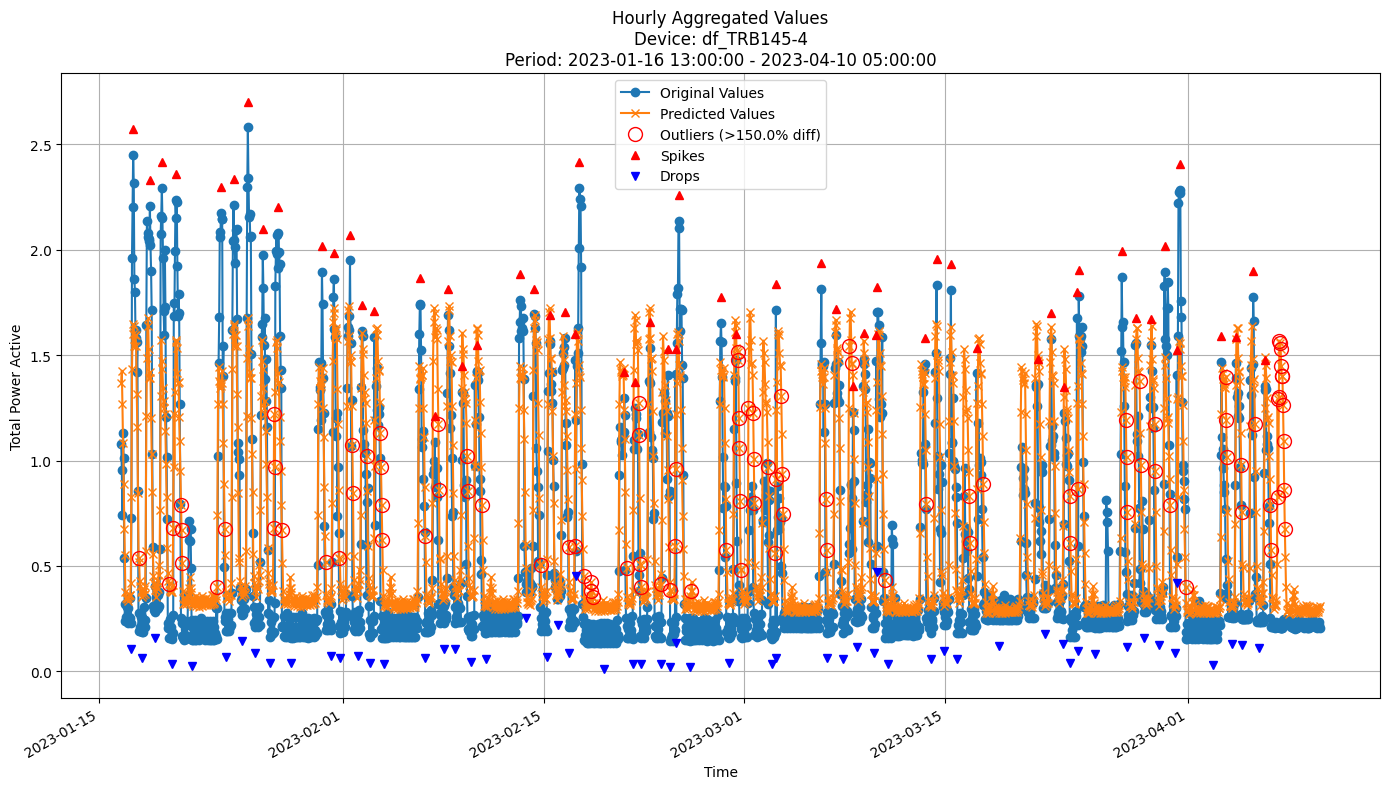


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3034
MAE: 0.2180
MAPE: 58.1053%

Directional Metrics:
Directional Accuracy: 59.3423%
First-Diff Correlation: 0.6333

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2203
  Recall: 0.2203
  F1 Score: 0.2203
Drops:
  Precision: 0.1017
  Recall: 0.1017
  F1 Score: 0.1017

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5593
  Recall: 0.5593
  F1 Score: 0.5593
Drops:
  Precision: 0.1864
  Recall: 0.1864
  F1 Score: 0.1864


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1h"
bl_prev = PreviousValueRegressor
bl_prev_params = {}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2184
	MAE: 0.1113
	MAPE: 13.9118%

Directional Metrics:
	Directional Accuracy: 11.2765%
	First-Diff Correlation: 0.036

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 0.000412 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2322
	MAE: 0.1151
	MAPE: 21.8981%

Directional Metrics:
	Directional Accuracy: 12.3930%
	First-Diff Correlation: 0.056

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 0.000389 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2116
	MAE: 0.1100
	MAPE: 28.3538%

Directional Metrics:
	Directional Accuracy: 12.0953%
	First-Diff Correlation: 0.034

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 0.000381 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1988
	MAE: 0.1011
	MAPE: 21.8713%

Directional Metrics:
	Directional Accuracy: 10.7008%
	First-Diff Correlation: 0.003

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.2101 ± 0.0204
	MAE: 0.1068 ± 0.0114
	MAPE: 21.5092% ± 5.0289%

	Directional Metrics:
		Directional Accuracy: 11.9993% ± 0.8914%
		First-Diff Correlation: 0.0528 ± 0.0328

	Immediate Detection (delta=0):
		Spike Precision: 0.0828 ± 0.0606
		Spike Recall: 0.0670 ± 0.0485
		Spike F1: 0.0738 ± 0.0533
		Drop Precision: 0.0783 ± 0.0641
		Drop Recall: 0.0689 ± 0.0663
		Drop F1: 0.0729 ± 0.0653

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2767 ± 0.1163
		Spike Recall: 0.2294 ± 0.0665
		Spike F1: 0.2496 ± 0.0865
		Drop Precision: 0.1826 ± 0.0526
		Drop Recall: 0.1558 ± 0.0482
		Drop F1: 0.1674 ± 0.0495
Hourly Metrics:
	RMSE: 0.1828 ± 0.0188
	MAE: 0.1013 ± 0.0108
	MAPE: 19.7203% ± 4.4735%

	Directional Metrics:
		Directional Accuracy: 58.5057% ± 4.1851%
		First-Diff Correlation: 0.4544 ± 0.0551

	Immediate Detection (delta=0):

#### Validation plots

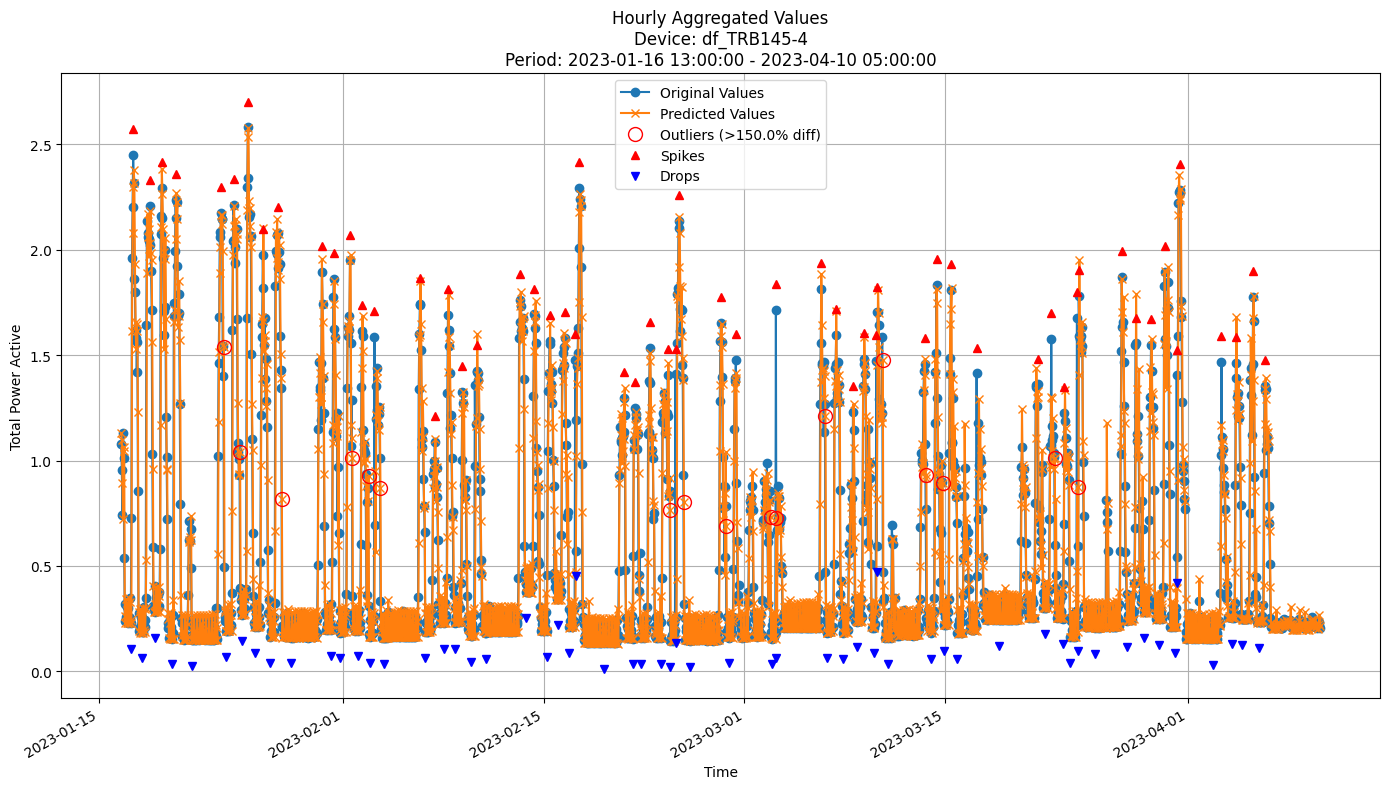


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1870
MAE: 0.1044
MAPE: 23.3244%

Directional Metrics:
Directional Accuracy: 56.6517%
First-Diff Correlation: 0.4319

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2222
  Recall: 0.1695
  F1 Score: 0.1923
Drops:
  Precision: 0.0682
  Recall: 0.0508
  F1 Score: 0.0583

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.6102
  F1 Score: 0.6923
Drops:
  Precision: 0.4545
  Recall: 0.3390
  F1 Score: 0.3883


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)


# Results from hyperparam. tuning
# RMSE (best: 0.230)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.8, 'random_state': 42}
# MAE (best: 0.143)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# MAPE (best: 28.070%)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# DIR_ACCURACY (best: 62.673%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 12, 'subsample': 0.8, 'random_state': 42}
# FIRST_DIFF_CORR (best: 42.984%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# SPIKES_F1 (best: 20.873%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# DROPS_F1 (best: 15.373%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.15, 'max_depth': 15, 'subsample': 0.8, 'random_state': 42}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 5.94 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 9.17 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3120
	MAE: 0.1877
	MAPE: 21.4370%

Directional Metrics:
	Directional Accuracy: 53.4053%
	First-Diff Correlation: 0.0590

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 12.65 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 16.26 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.010735 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2664
	MAE: 0.1709
	MAPE: 39.2053%

Directional Metrics:
	Directional Accuracy: 55.0800%
	First-Diff Correlation: 0.0959

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0667
		F1: 0.0588
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 32.36 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 35.79 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.010506 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2309
	MAE: 0.1607
	MAPE: 48.0109%

Directional Metrics:
	Directional Accuracy: 51.7678%
	First-Diff Correlation: 0.2094

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0500
		F1: 0.0513
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 39.01 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 42.79 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.010429 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2346
	MAE: 0.1468
	MAPE: 37.0374%

Directional Metrics:
	Directional Accuracy: 51.2811%
	First-Diff Correlation: 0.0988

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection del

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.0503 ± 0.0117
	MAE: 0.0378 ± 0.0083
	MAPE: 8.5307% ± 2.3962%

	Directional Metrics:
		Directional Accuracy: 74.3758% ± 2.7236%
		First-Diff Correlation: 0.9496 ± 0.0264

	Immediate Detection (delta=0):
		Spike Precision: 0.8652 ± 0.1927
		Spike Recall: 0.6269 ± 0.2577
		Spike F1: 0.6789 ± 0.2441
		Drop Precision: 0.0115 ± 0.0178
		Drop Recall: 0.0126 ± 0.0200
		Drop F1: 0.0120 ± 0.0188

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9335 ± 0.1015
		Spike Recall: 0.6996 ± 0.2796
		Spike F1: 0.7493 ± 0.2462
		Drop Precision: 0.0649 ± 0.0723
		Drop Recall: 0.0575 ± 0.0664
		Drop F1: 0.0597 ± 0.0664
Hourly Metrics:
	RMSE: 0.0403 ± 0.0087
	MAE: 0.0302 ± 0.0059
	MAPE: 6.5027% ± 1.6014%

	Directional Metrics:
		Directional Accuracy: 91.9068% ± 2.0034%
		First-Diff Correlation: 0.9895 ± 0.0063

	Immediate Detection (delta=0):
	

#### Training plots

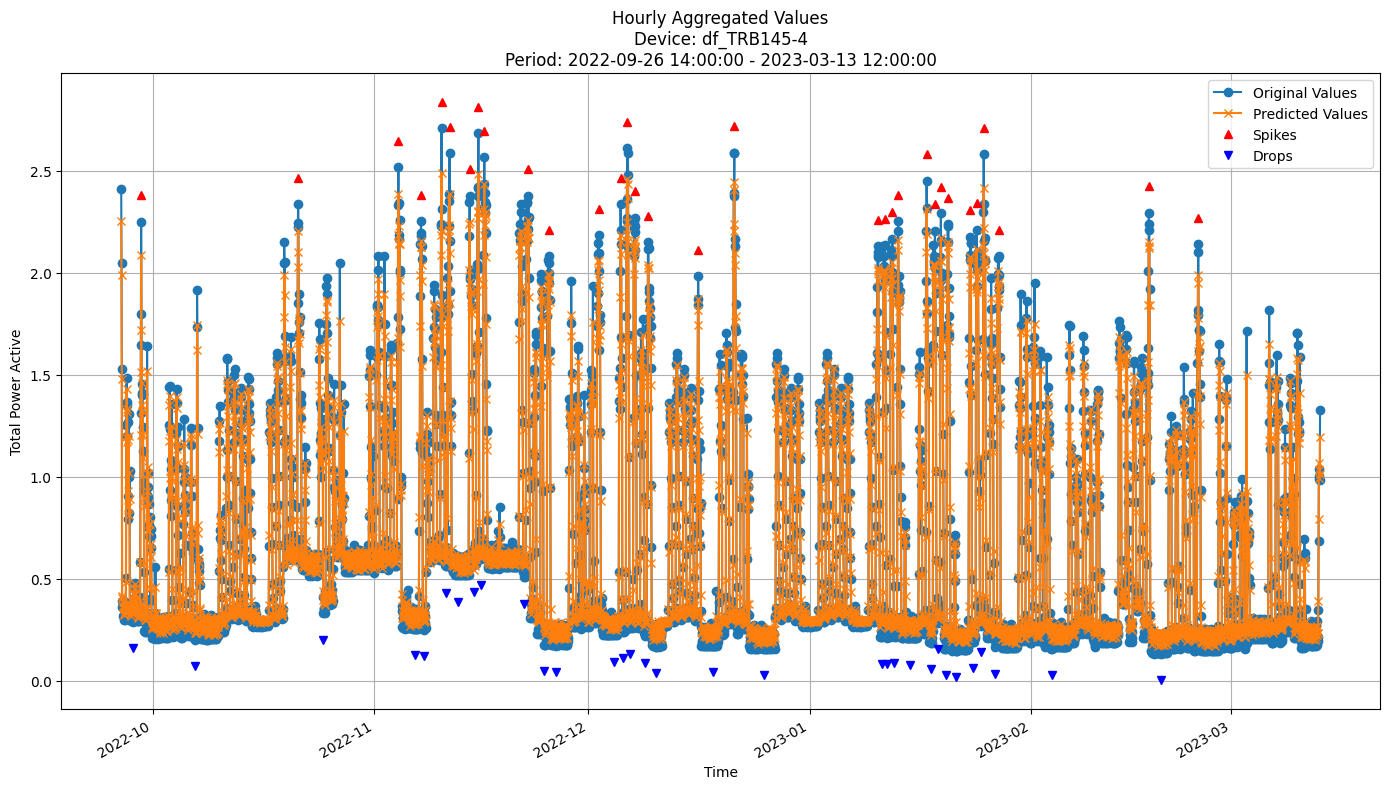


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0513
MAE: 0.0374
MAPE: 8.7771%

Directional Metrics:
Directional Accuracy: 89.5807%
First-Diff Correlation: 0.9805

Immediate Detection (delta=0):
Spikes:
  Precision: 0.7143
  Recall: 0.7812
  F1 Score: 0.7463
Drops:
  Precision: 0.2000
  Recall: 0.2188
  F1 Score: 0.2090

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7714
  Recall: 0.8438
  F1 Score: 0.8060
Drops:
  Precision: 0.2000
  Recall: 0.2188
  F1 Score: 0.2090


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

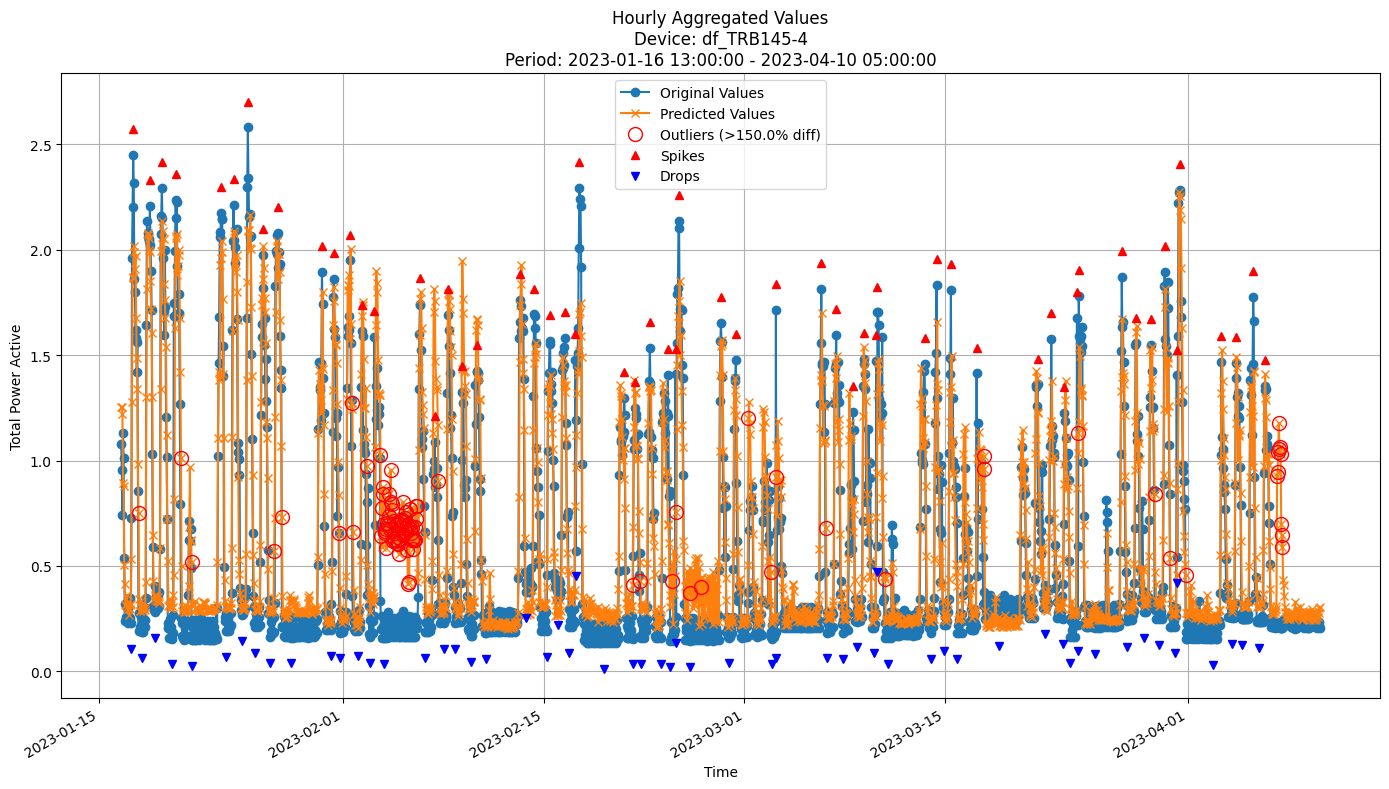


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2266
MAE: 0.1538
MAPE: 42.7439%

Directional Metrics:
Directional Accuracy: 59.8904%
First-Diff Correlation: 0.4883

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1111
  Recall: 0.1017
  F1 Score: 0.1062
Drops:
  Precision: 0.1132
  Recall: 0.1017
  F1 Score: 0.1071

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5556
  Recall: 0.5085
  F1 Score: 0.5310
Drops:
  Precision: 0.1887
  Recall: 0.1695
  F1 Score: 0.1786


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

# Results from hyperparam. tuning
# BEST RMSE: 0.230
#    Best Parameters: {'n_estimators': 150, 'max_depth': 15, 'max_features': 0.5, 'random_state': 42, 'n_jobs': -1}
# BEST MAE: 0.140
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST MAPE: 27.282%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DIR_ACCURACY: 63.559%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST FIRST_DIFF_CORR: 44.507%
#    Best Parameters: {'n_estimators': 300, 'max_depth': 5, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}
# BEST SPIKES_F1: 20.414%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 5, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DROPS_F1: 14.260%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}

In [21]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00

Time: 0.15 seconds
Predicting for chunk from 2022-10-24 14:00:00+02:00 to 2022-11-07 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-07 13:00:00+01:00

Time: 0.19 seconds
Predicting for chunk from 2022-11-07 13:15:00+01:00 to 2022-11-21 12:45:00+01:00

-------------------------
Model's memory usage: 0.042160 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3101
	MAE: 0.1944
	MAPE: 22.4083%

Directional Metrics:
	Directional Accuracy: 52.6610%
	First-Diff Correlation: 0.0779

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1111
		Recall: 0.0526
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00

Time: 0.25 seconds
Predicting for chunk from 2022-11-21 13:00:00+01:00 to 2022-12-05 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2022-12-05 13:00:00+01:00

Time: 0.32 seconds
Predicting for chunk from 2022-12-05 13:15:00+01:00 to 2022-12-19 12:45:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2584
	MAE: 0.1647
	MAPE: 36.7917%

Directional Metrics:
	Directional Accuracy: 56.3454%
	First-Diff Correlation: 0.1391

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00

Time: 0.55 seconds
Predicting for chunk from 2023-02-13 13:00:00+01:00 to 2023-02-27 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-02-27 13:00:00+01:00

Time: 0.69 seconds
Predicting for chunk from 2023-02-27 13:15:00+01:00 to 2023-03-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2322
	MAE: 0.1530
	MAPE: 41.9409%

Directional Metrics:
	Directional Accuracy: 51.3956%
	First-Diff Correlation: 0.2471

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0500
		F1: 0.0513
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00

Time: 0.77 seconds
Predicting for chunk from 2023-03-13 13:00:00+01:00 to 2023-03-27 14:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-03-27 14:00:00+02:00

Time: 0.73 seconds
Predicting for chunk from 2023-03-27 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2298
	MAE: 0.1467
	MAPE: 35.0661%

Directional Metrics:
	Directional Accuracy: 51.3564%
	First-Diff Correlation: 0.1543

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0800
		F1: 0.0889
	Drops:
		Precision: 0.0500
		Recall: 0.0400
		F1: 0.0444

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.1071 ± 0.0190
	MAE: 0.0659 ± 0.0127
	MAPE: 12.3052% ± 3.1650%

	Directional Metrics:
		Directional Accuracy: 68.2649% ± 1.8284%
		First-Diff Correlation: 0.7700 ± 0.0657

	Immediate Detection (delta=0):
		Spike Precision: 0.1810 ± 0.1829
		Spike Recall: 0.1306 ± 0.1362
		Spike F1: 0.1503 ± 0.1536
		Drop Precision: 0.0074 ± 0.0166
		Drop Recall: 0.0060 ± 0.0133
		Drop F1: 0.0066 ± 0.0148

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3593 ± 0.3892
		Spike Recall: 0.2636 ± 0.3050
		Spike F1: 0.3014 ± 0.3382
		Drop Precision: 0.0111 ± 0.0248
		Drop Recall: 0.0089 ± 0.0200
		Drop F1: 0.0099 ± 0.0221
Hourly Metrics:
	RMSE: 0.0858 ± 0.0180
	MAE: 0.0524 ± 0.0112
	MAPE: 9.1920% ± 2.4281%

	Directional Metrics:
		Directional Accuracy: 82.2098% ± 3.1980%
		First-Diff Correlation: 0.8985 ± 0.0355

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

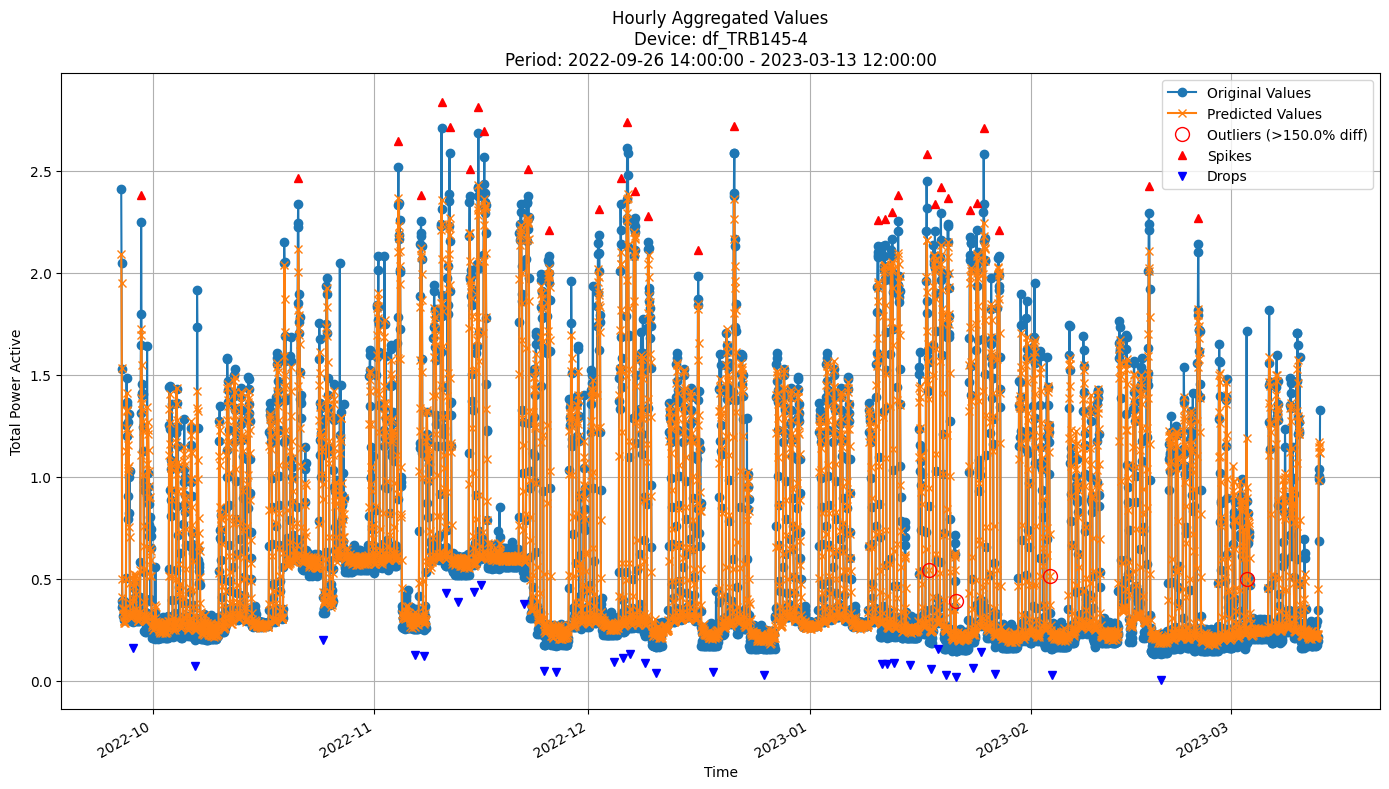


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1071
MAE: 0.0660
MAPE: 12.8762%

Directional Metrics:
Directional Accuracy: 78.5413%
First-Diff Correlation: 0.8548

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5600
  Recall: 0.4375
  F1 Score: 0.4912
Drops:
  Precision: 0.1200
  Recall: 0.0938
  F1 Score: 0.1053

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7200
  Recall: 0.5625
  F1 Score: 0.6316
Drops:
  Precision: 0.2000
  Recall: 0.1562
  F1 Score: 0.1754


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

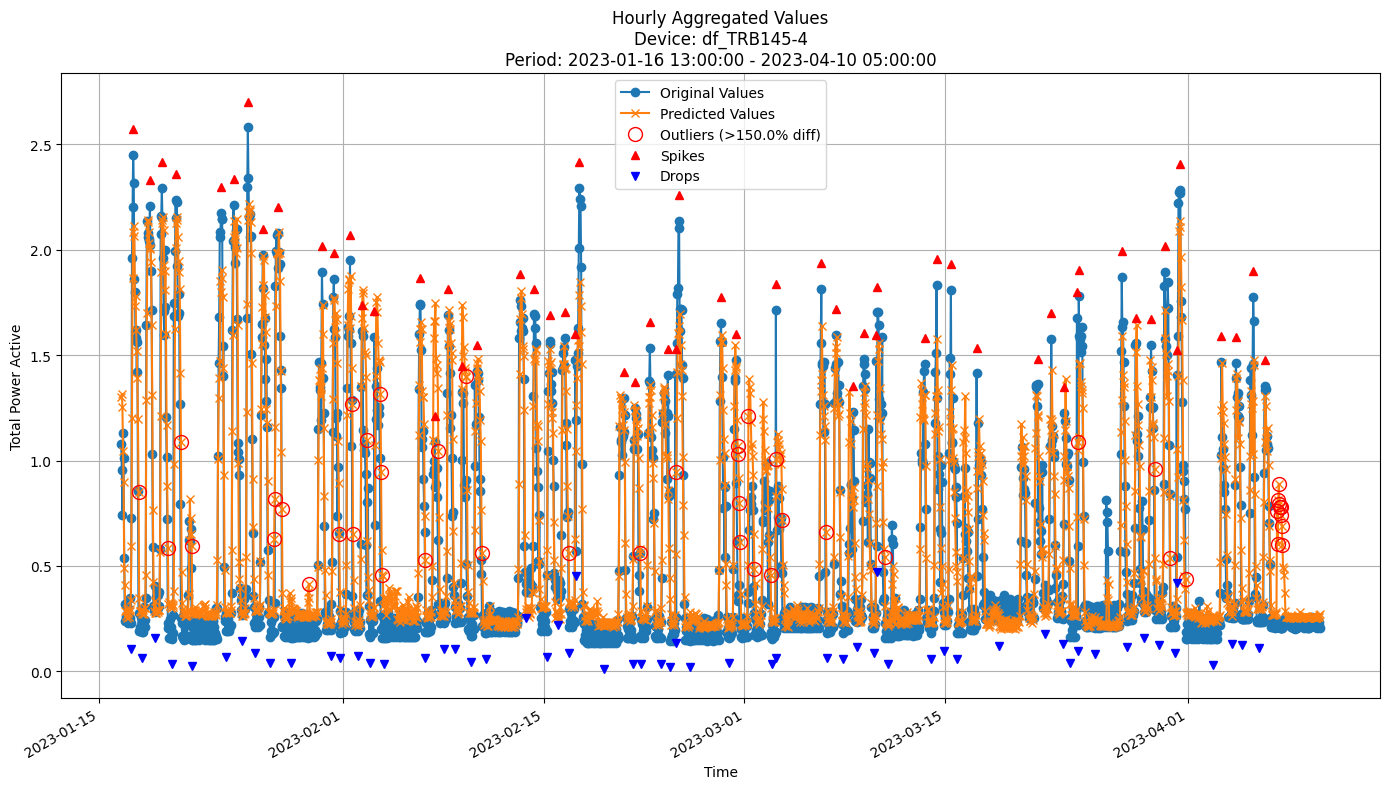


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2192
MAE: 0.1411
MAPE: 34.2000%

Directional Metrics:
Directional Accuracy: 56.0538%
First-Diff Correlation: 0.4677

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0690
  Recall: 0.0678
  F1 Score: 0.0684
Drops:
  Precision: 0.0517
  Recall: 0.0508
  F1 Score: 0.0513

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5172
  Recall: 0.5085
  F1 Score: 0.5128
Drops:
  Precision: 0.1897
  Recall: 0.1864
  F1 Score: 0.1880


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


# Results from hyperparam. tuning
# BEST RMSE: 0.258
#    Best Parameters: {'max_depth': 10, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAE: 0.162
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAPE: 30.209%
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST DIR_ACCURACY: 54.170%
#    Best Parameters: {'max_depth': 5, 'grace_period': 0, 'tau': 0.1, 'delta': 0.005}
# BEST FIRST_DIFF_CORR: 41.677%
#    Best Parameters: {'max_depth': 3, 'grace_period': 0, 'tau': 0.1, 'delta': 0.05}
# BEST SPIKES_F1: 18.787%
#    Best Parameters: {'max_depth': 3, 'grace_period': 24, 'tau': 0.001, 'delta': 0.05}
# BEST DROPS_F1: 10.620%
#    Best Parameters: {'max_depth': 10, 'grace_period': 24, 'tau': 0.1, 'delta': 0.005}


In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 3.682381 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5097
	MAE: 0.3443
	MAPE: 41.7360%

Directional Metrics:
	Directional Accuracy: 25.6792%
	First-Diff Correlation: 0.055

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 4.524796 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4044
	MAE: 0.2781
	MAPE: 63.3453%

Directional Metrics:
	Directional Accuracy: 25.9025%
	First-Diff Correlation: 0.047

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 6.470604 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3298
	MAE: 0.2158
	MAPE: 57.6308%

Directional Metrics:
	Directional Accuracy: 25.2698%
	First-Diff Correlation: 0.064

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 6.518692 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3562
	MAE: 0.2246
	MAPE: 53.6620%

Directional Metrics:
	Directional Accuracy: 27.3173%
	First-Diff Correlation: 0.060

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3612 ± 0.0257
	MAE: 0.2304 ± 0.0217
	MAPE: 42.9947% ± 5.9492%

	Directional Metrics:
		Directional Accuracy: 20.3999% ± 1.1610%
		First-Diff Correlation: 0.0843 ± 0.0044

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0031 ± 0.0070
		Drop Recall: 0.0060 ± 0.0133
		Drop F1: 0.0041 ± 0.0092

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0051 ± 0.0115
		Spike Recall: 0.0060 ± 0.0133
		Spike F1: 0.0055 ± 0.0123
		Drop Precision: 0.0140 ± 0.0201
		Drop Recall: 0.0186 ± 0.0326
		Drop F1: 0.0149 ± 0.0233
Hourly Metrics:
	RMSE: 0.3220 ± 0.0250
	MAE: 0.2073 ± 0.0214
	MAPE: 38.0690% ± 6.0808%

	Directional Metrics:
		Directional Accuracy: 53.8905% ± 0.9598%
		First-Diff Correlation: 0.3545 ± 0.0305

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

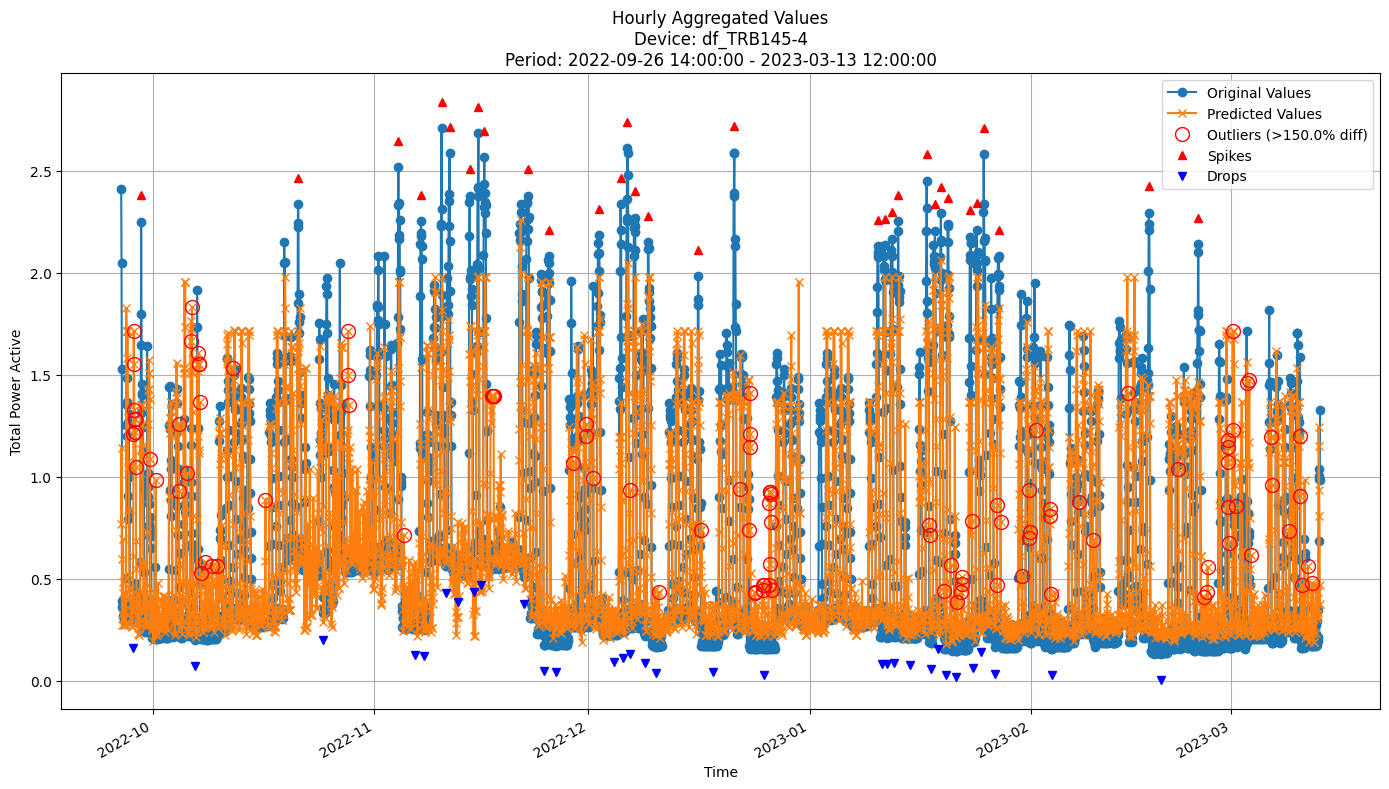


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2927
MAE: 0.1838
MAPE: 34.6425%

Directional Metrics:
Directional Accuracy: 53.2870%
First-Diff Correlation: 0.3860

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1579
  Recall: 0.0938
  F1 Score: 0.1176
Drops:
  Precision: 0.1053
  Recall: 0.0625
  F1 Score: 0.0784

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1579
  Recall: 0.0938
  F1 Score: 0.1176
Drops:
  Precision: 0.1053
  Recall: 0.0625
  F1 Score: 0.0784


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

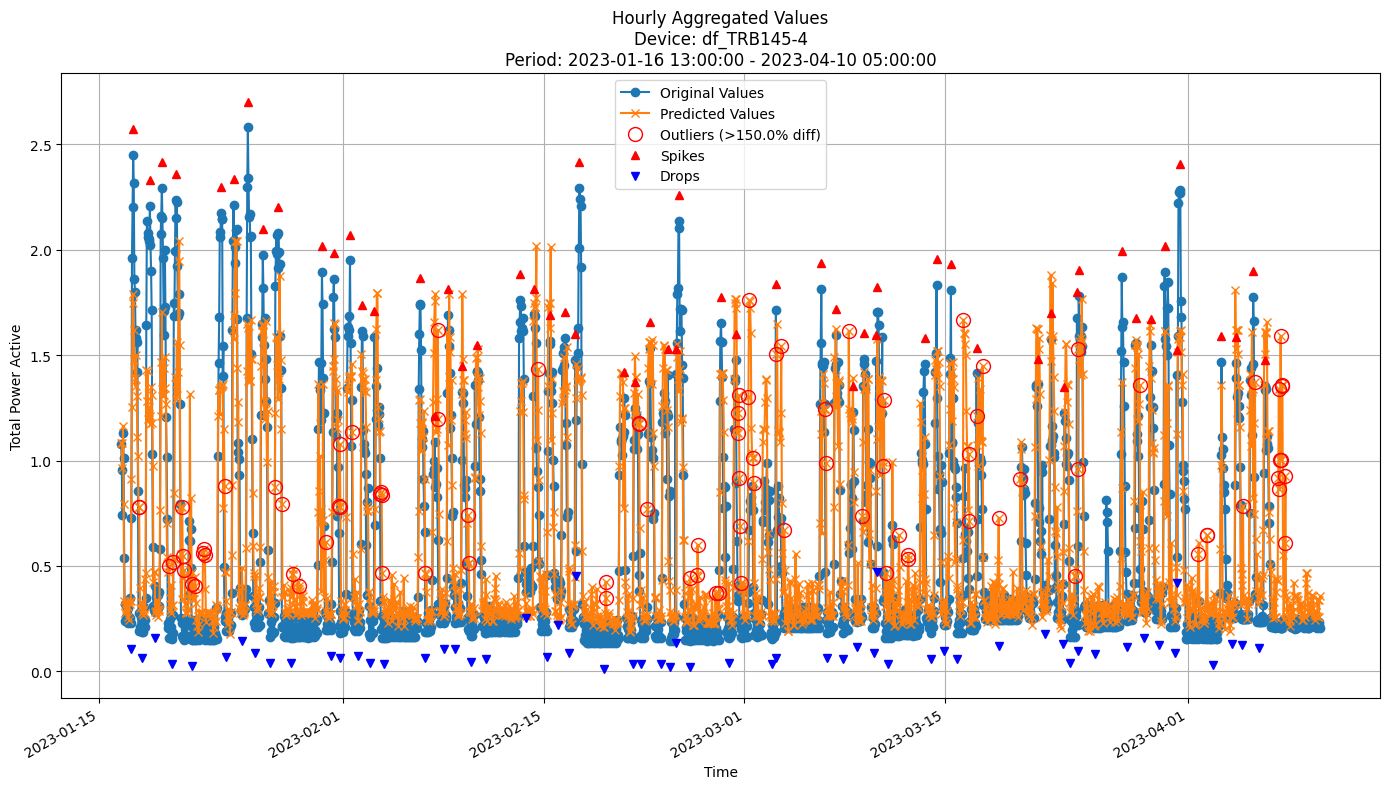


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3065
MAE: 0.2033
MAPE: 48.4428%

Directional Metrics:
Directional Accuracy: 53.7120%
First-Diff Correlation: 0.3576

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1333
  Recall: 0.1356
  F1 Score: 0.1345
Drops:
  Precision: 0.0678
  Recall: 0.0678
  F1 Score: 0.0678

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3333
  Recall: 0.3390
  F1 Score: 0.3361
Drops:
  Precision: 0.1695
  Recall: 0.1695
  F1 Score: 0.1695


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [31]:

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 20.793190 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3708
	MAE: 0.2303
	MAPE: 24.0572%

Directional Metrics:
	Directional Accuracy: 42.7614%
	First-Diff Correlation: 0.07

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 28.986252 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2937
	MAE: 0.2023
	MAPE: 45.0250%

Directional Metrics:
	Directional Accuracy: 45.9993%
	First-Diff Correlation: 0.08

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 40.970139 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2835
	MAE: 0.1892
	MAPE: 51.9589%

Directional Metrics:
	Directional Accuracy: 45.2177%
	First-Diff Correlation: 0.09

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 43.338272 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2552
	MAE: 0.1683
	MAPE: 39.8235%

Directional Metrics:
	Directional Accuracy: 44.2351%
	First-Diff Correlation: 0.08

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.2568 ± 0.0112
	MAE: 0.1608 ± 0.0095
	MAPE: 29.5457% ± 1.0466%

	Directional Metrics:
		Directional Accuracy: 46.6980% ± 0.7769%
		First-Diff Correlation: 0.1643 ± 0.0089

	Immediate Detection (delta=0):
		Spike Precision: 0.0254 ± 0.0385
		Spike Recall: 0.0186 ± 0.0326
		Spike F1: 0.0209 ± 0.0348
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0409 ± 0.0587
		Spike Recall: 0.0282 ± 0.0462
		Spike F1: 0.0324 ± 0.0501
		Drop Precision: 0.0125 ± 0.0205
		Drop Recall: 0.0067 ± 0.0095
		Drop F1: 0.0084 ± 0.0125
Hourly Metrics:
	RMSE: 0.2337 ± 0.0104
	MAE: 0.1489 ± 0.0093
	MAPE: 26.4395% ± 1.3297%

	Directional Metrics:
		Directional Accuracy: 64.5020% ± 2.5702%
		First-Diff Correlation: 0.5401 ± 0.0385

	Immediate Detection (delta=0):

#### Training plots

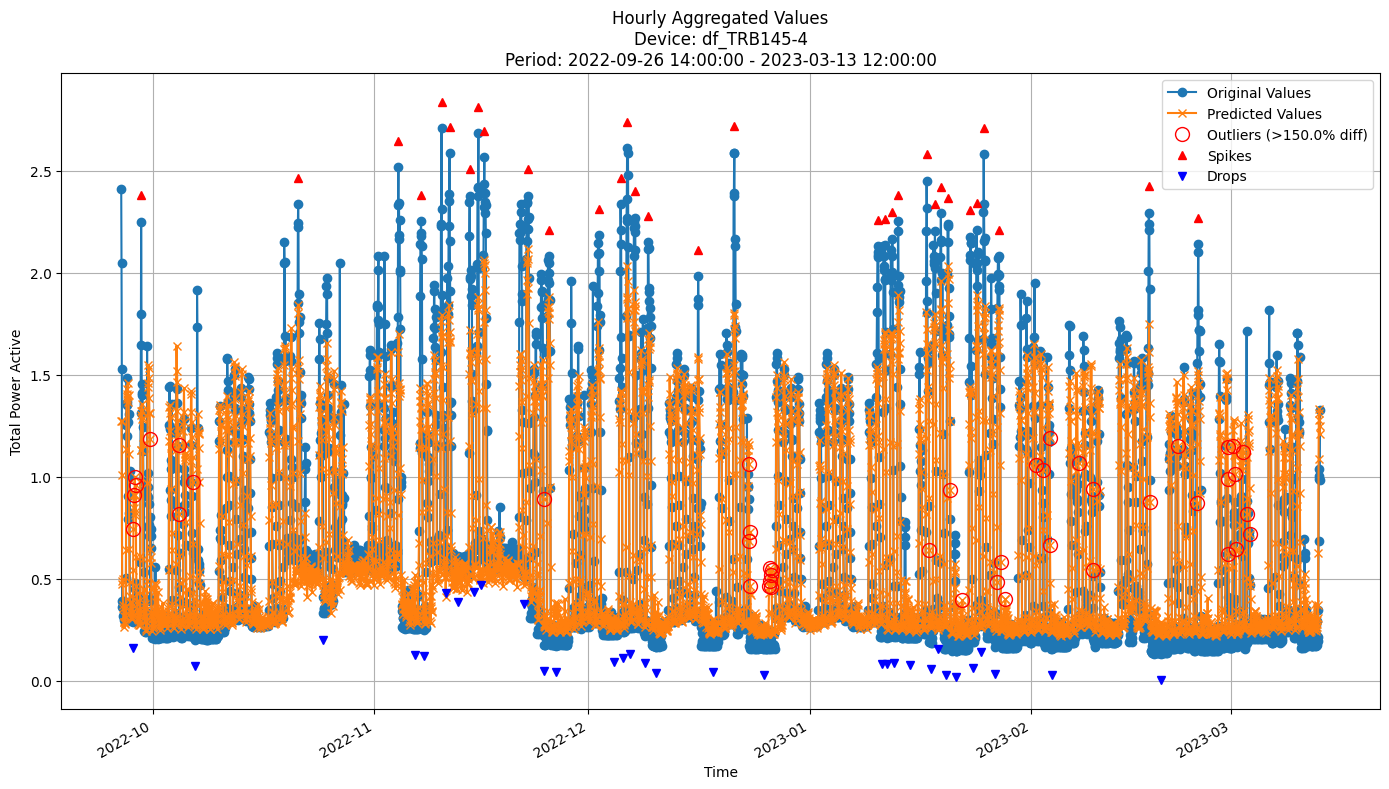


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2330
MAE: 0.1442
MAPE: 26.3179%

Directional Metrics:
Directional Accuracy: 62.0194%
First-Diff Correlation: 0.5584

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2353
  Recall: 0.1250
  F1 Score: 0.1633
Drops:
  Precision: 0.0625
  Recall: 0.0312
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8235
  Recall: 0.4375
  F1 Score: 0.5714
Drops:
  Precision: 0.1875
  Recall: 0.0938
  F1 Score: 0.1250


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

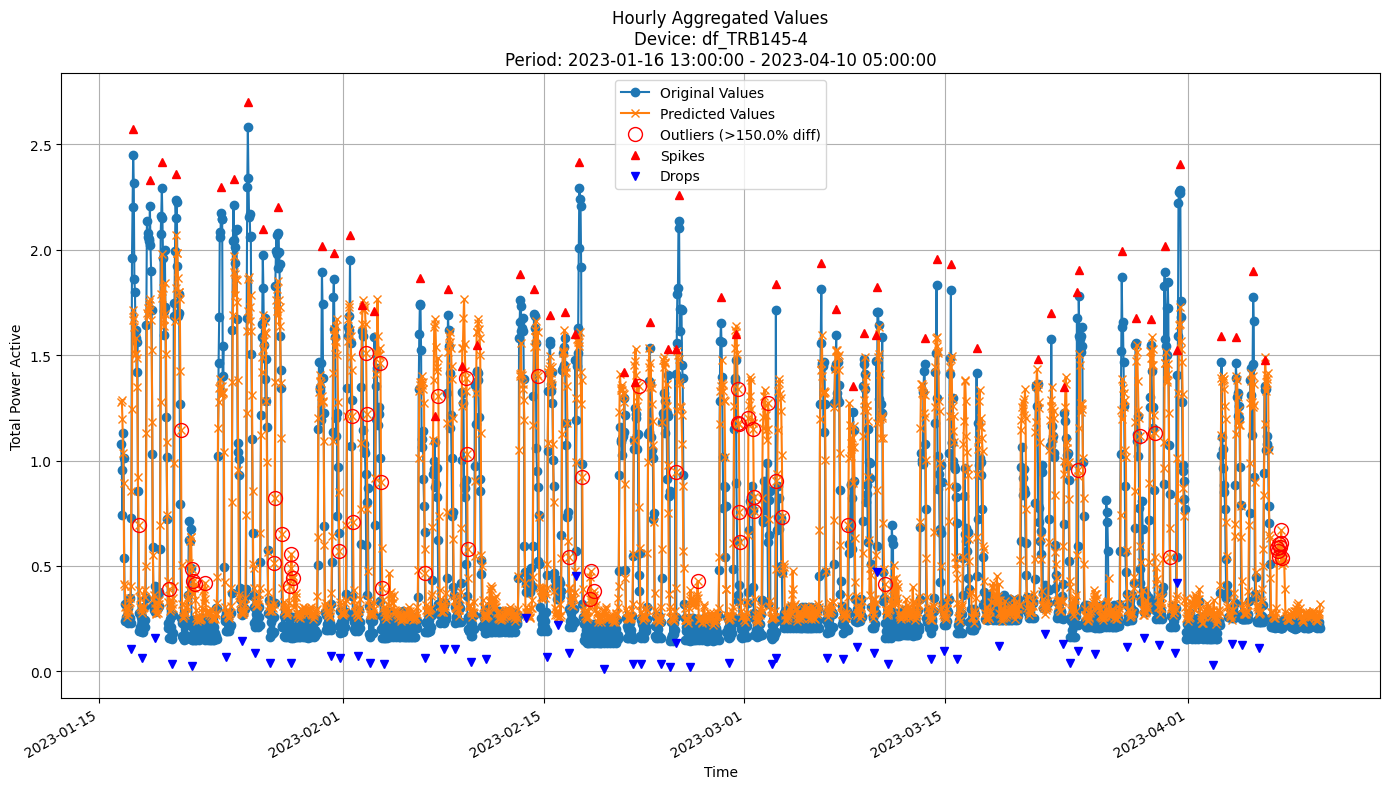


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2538
MAE: 0.1689
MAPE: 40.7690%

Directional Metrics:
Directional Accuracy: 52.5162%
First-Diff Correlation: 0.4204

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1034
  Recall: 0.1017
  F1 Score: 0.1026
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.4915
  F1 Score: 0.4957
Drops:
  Precision: 0.2241
  Recall: 0.2203
  F1 Score: 0.2222


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

# Results from hyperparam. tuning
# BEST RMSE: 0.284
#    Best Parameters: {'depth': 100, 'grace_period': 24, 'grace_period_depth': -1, 'split_confidence': 0.5, 'max_feature': 0.7, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAE: 0.166
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAPE: 30.526%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DIR_ACCURACY: 56.835%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.5, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST FIRST_DIFF_CORR: 39.216%
#    Best Parameters: {'depth': 5, 'grace_period': 96, 'grace_period_depth': 1, 'split_confidence': 0.005, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST SPIKES_F1: 28.855%
#    Best Parameters: {'depth': 5, 'grace_period': 10, 'grace_period_depth': 1, 'split_confidence': 0.5, 'max_feature': 0.5, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DROPS_F1: 16.382%
#    Best Parameters: {'depth': 50, 'grace_period': 48, 'grace_period_depth': 0, 'split_confidence': 0.01, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 5.677048 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3753
	MAE: 0.2152
	MAPE: 25.1636%

Directional Metrics:
	Directional Accuracy: 36.2114%
	First-Diff Correlation: 0.011

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 21.025833 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3716
	MAE: 0.2183
	MAPE: 44.4846%

Directional Metrics:
	Directional Accuracy: 35.0205%
	First-Diff Correlation: 0.06

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 61.799538 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3904
	MAE: 0.2255
	MAPE: 49.1188%

Directional Metrics:
	Directional Accuracy: 37.6628%
	First-Diff Correlation: 0.00

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 80.246216 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3488
	MAE: 0.2026
	MAPE: 43.1925%

Directional Metrics:
	Directional Accuracy: 40.2411%
	First-Diff Correlation: 0.00

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3571 ± 0.0205
	MAE: 0.1891 ± 0.0174
	MAPE: 32.0683% ± 6.6718%

	Directional Metrics:
		Directional Accuracy: 36.6293% ± 5.1626%
		First-Diff Correlation: 0.0962 ± 0.0310

	Immediate Detection (delta=0):
		Spike Precision: 0.1026 ± 0.1787
		Spike Recall: 0.1019 ± 0.0792
		Spike F1: 0.0718 ± 0.0846
		Drop Precision: 0.0136 ± 0.0141
		Drop Recall: 0.0446 ± 0.0491
		Drop F1: 0.0207 ± 0.0217

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1248 ± 0.1709
		Spike Recall: 0.1725 ± 0.0962
		Spike F1: 0.1055 ± 0.0806
		Drop Precision: 0.0183 ± 0.0190
		Drop Recall: 0.0579 ± 0.0595
		Drop F1: 0.0277 ± 0.0285
Hourly Metrics:
	RMSE: 0.2909 ± 0.0252
	MAE: 0.1626 ± 0.0189
	MAPE: 27.3189% ± 7.0217%

	Directional Metrics:
		Directional Accuracy: 63.9266% ± 1.7554%
		First-Diff Correlation: 0.4166 ± 0.0356

	Immediate Detection (delta=0):

#### Training plots


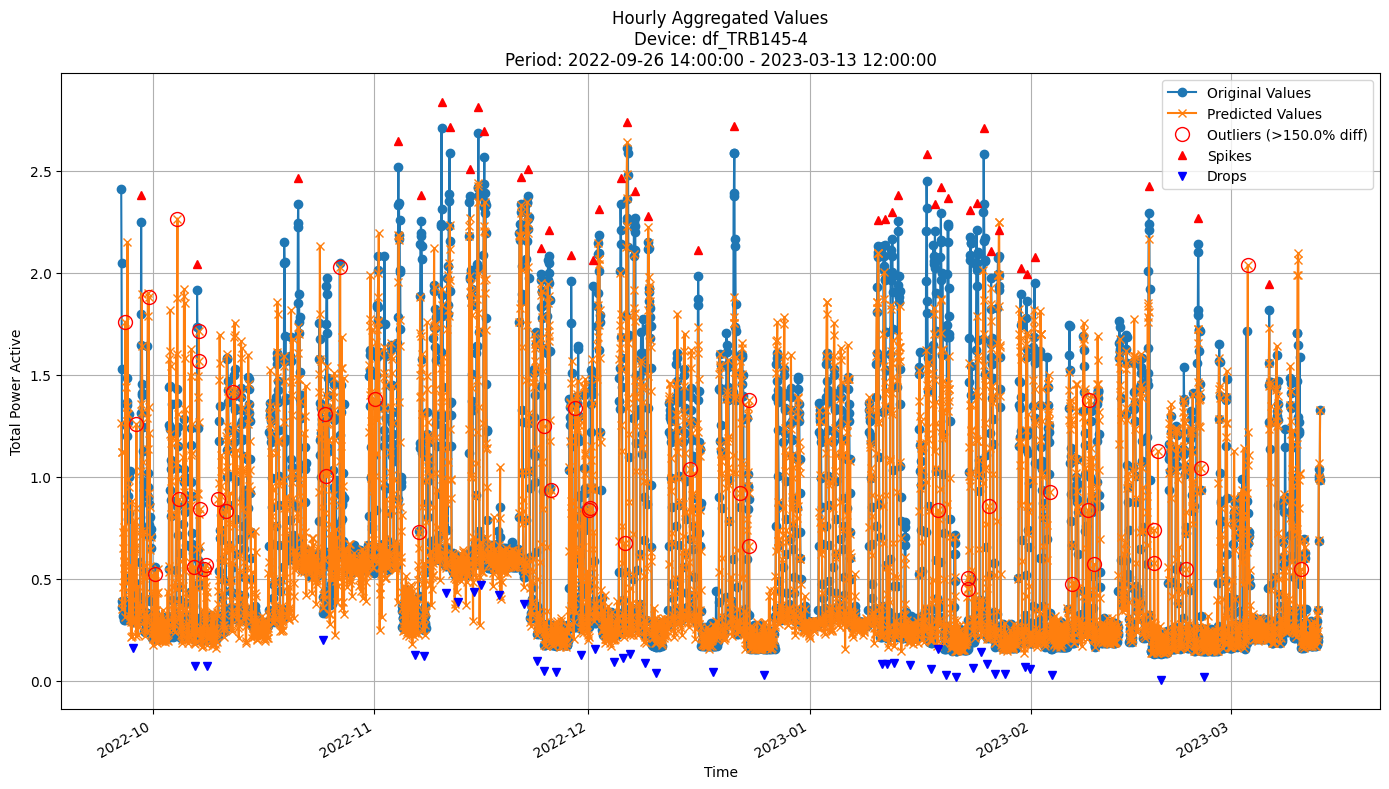


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2513
MAE: 0.1390
MAPE: 21.7416%

Directional Metrics:
Directional Accuracy: 62.2922%
First-Diff Correlation: 0.4348

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1600
  Recall: 0.0952
  F1 Score: 0.1194
Drops:
  Precision: 0.0833
  Recall: 0.0476
  F1 Score: 0.0606

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4000
  Recall: 0.2381
  F1 Score: 0.2985
Drops:
  Precision: 0.1250
  Recall: 0.0714
  F1 Score: 0.0909


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

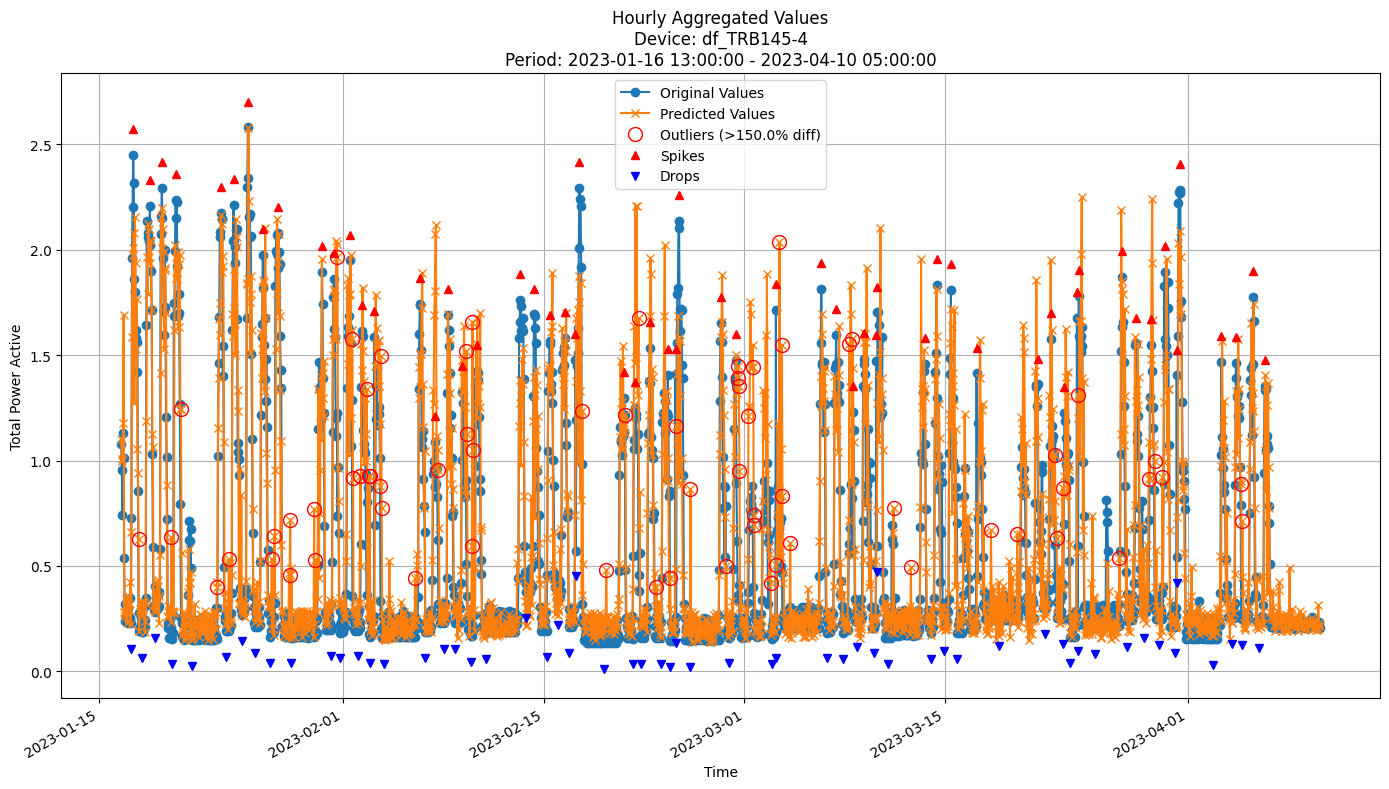


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2865
MAE: 0.1713
MAPE: 36.2168%

Directional Metrics:
Directional Accuracy: 53.3632%
First-Diff Correlation: 0.2598

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0952
  Recall: 0.1017
  F1 Score: 0.0984
Drops:
  Precision: 0.0806
  Recall: 0.0847
  F1 Score: 0.0826

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3492
  Recall: 0.3729
  F1 Score: 0.3607
Drops:
  Precision: 0.2258
  Recall: 0.2373
  F1 Score: 0.2314


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [41]:

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 349.170547 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3788
	MAE: 0.2472
	MAPE: 35.5587%

Directional Metrics:
	Directional Accuracy: 48.3439%
	First-Diff Correlation: 0.0

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 435.621933 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3545
	MAE: 0.2578
	MAPE: 66.0384%

Directional Metrics:
	Directional Accuracy: 48.4183%
	First-Diff Correlation: 0.0

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 905.916862 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2753
	MAE: 0.1836
	MAPE: 49.0673%

Directional Metrics:
	Directional Accuracy: 50.1675%
	First-Diff Correlation: 0.0

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 1108.159698 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2481
	MAE: 0.1568
	MAPE: 37.0049%

Directional Metrics:
	Directional Accuracy: 49.6986%
	First-Diff Correlation: 0.

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.3966 ± 0.0400
	MAE: 0.2780 ± 0.0440
	MAPE: 54.6188% ± 23.5389%

	Directional Metrics:
		Directional Accuracy: 51.4460% ± 1.8741%
		First-Diff Correlation: 0.0957 ± 0.0183

	Immediate Detection (delta=0):
		Spike Precision: 0.0062 ± 0.0105
		Spike Recall: 0.0141 ± 0.0244
		Spike F1: 0.0086 ± 0.0147
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0267 ± 0.0210
		Spike Recall: 0.0925 ± 0.0899
		Spike F1: 0.0407 ± 0.0336
		Drop Precision: 0.0016 ± 0.0035
		Drop Recall: 0.0037 ± 0.0083
		Drop F1: 0.0022 ± 0.0049
Hourly Metrics:
	RMSE: 0.3758 ± 0.0431
	MAE: 0.2651 ± 0.0453
	MAPE: 50.8997% ± 23.4470%

	Directional Metrics:
		Directional Accuracy: 60.2671% ± 2.7484%
		First-Diff Correlation: 0.4423 ± 0.0766

	Immediate Detection (delta=0

#### Training plots

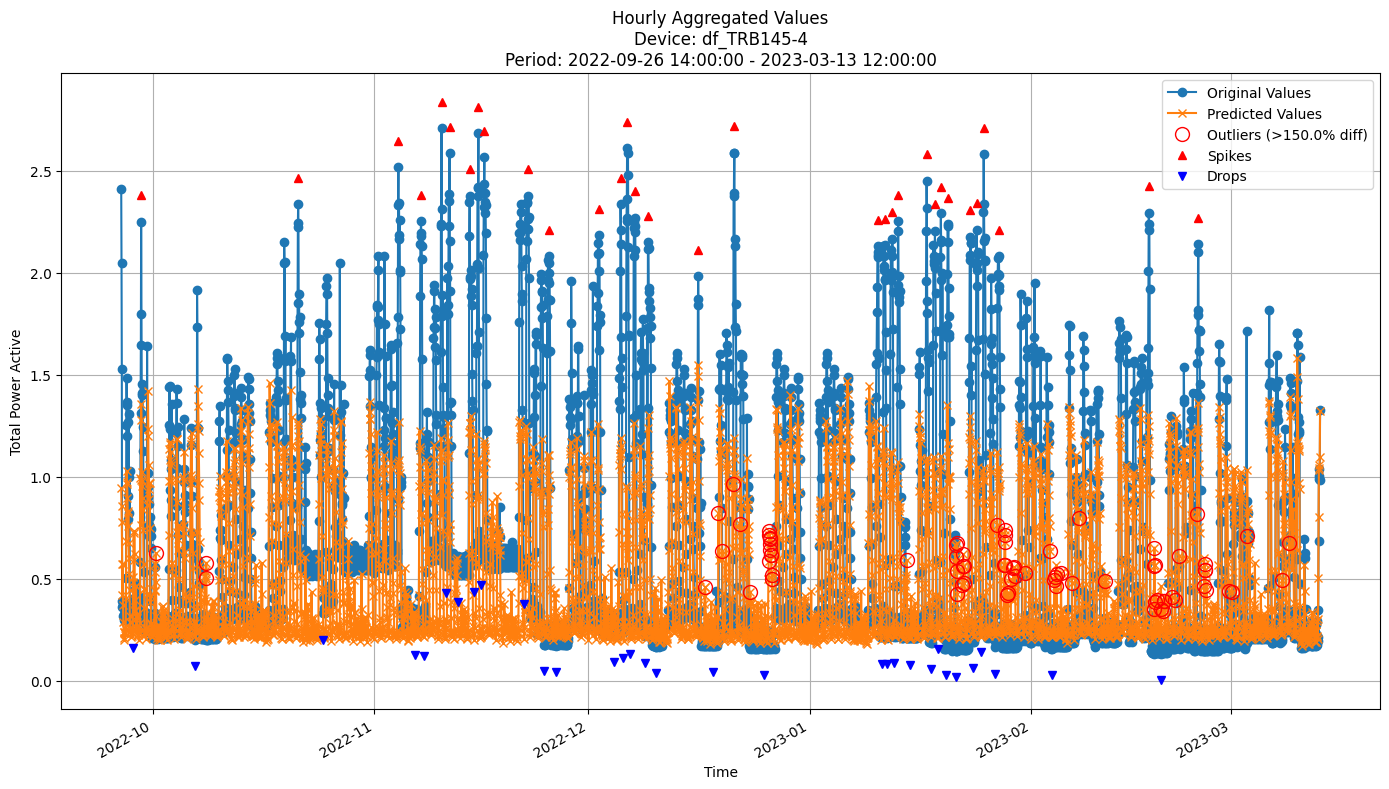


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3965
MAE: 0.2524
MAPE: 37.8254%

Directional Metrics:
Directional Accuracy: 57.0826%
First-Diff Correlation: 0.4642

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0435
  Recall: 0.0938
  F1 Score: 0.0594
Drops:
  Precision: 0.0145
  Recall: 0.0312
  F1 Score: 0.0198

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1304
  Recall: 0.2812
  F1 Score: 0.1782
Drops:
  Precision: 0.0435
  Recall: 0.0938
  F1 Score: 0.0594


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

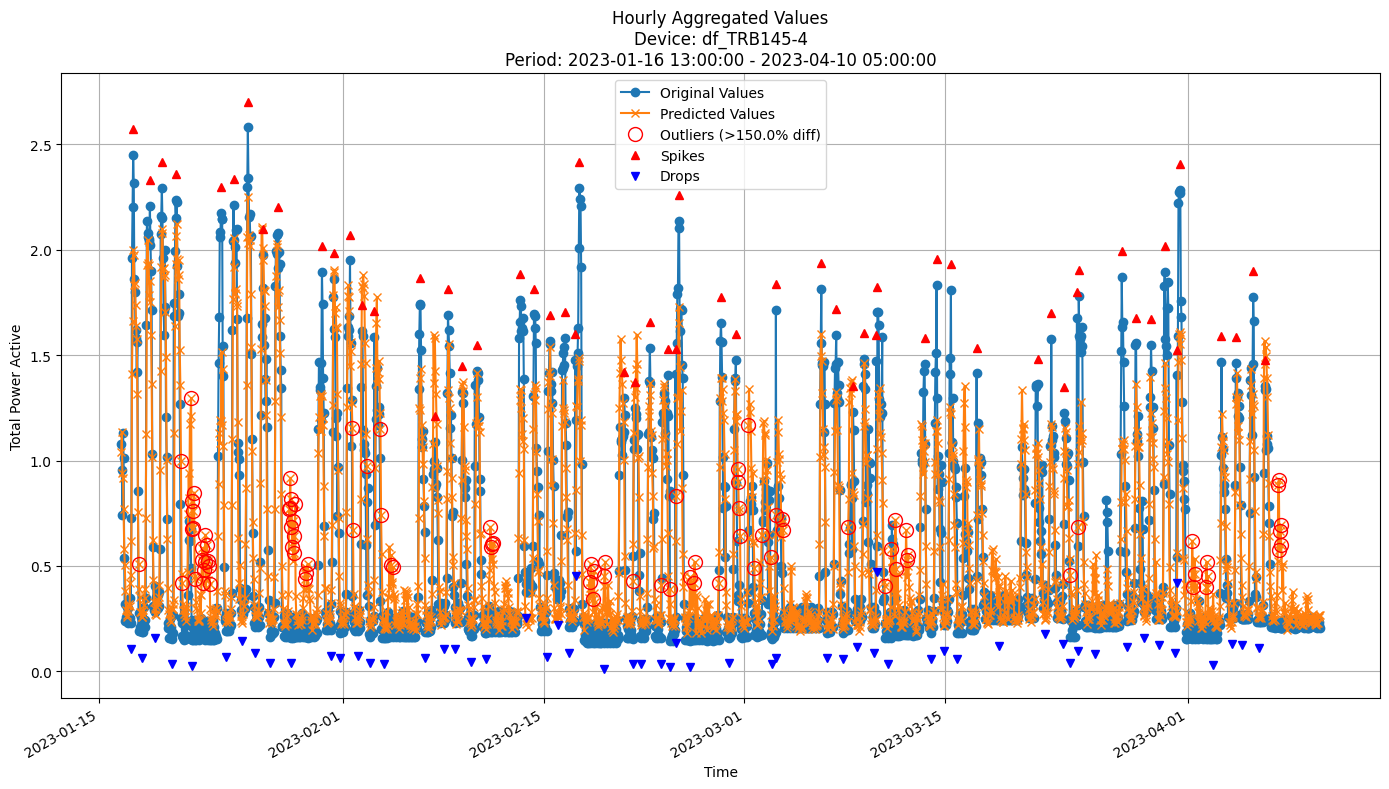


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2428
MAE: 0.1614
MAPE: 40.0304%

Directional Metrics:
Directional Accuracy: 56.5521%
First-Diff Correlation: 0.4620

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2250
  Recall: 0.1525
  F1 Score: 0.1818
Drops:
  Precision: 0.1026
  Recall: 0.0678
  F1 Score: 0.0816

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5500
  Recall: 0.3729
  F1 Score: 0.4444
Drops:
  Precision: 0.2564
  Recall: 0.1695
  F1 Score: 0.2041


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    base_learner=fastodt.FastODT,
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

# Results from hyperparam. tuning (might need to UPDATE after new drift detection method)
# BEST RMSE: 0.357
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAE: 0.276
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAPE: 61.889%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (70, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST SPIKES_F1: 6.190%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DROPS_F1: 0.000%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}

In [46]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-10-24 13:45:00+02:00
Model's memory usage: 1.585945 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-24 14:00:00+02:00 - 2022-11-21 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6047
	MAE: 0.4497
	MAPE: 48.1434%

Directional Metrics:
	Directional Accuracy: 15.6680%
	First-Diff Correlation: -0.00

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2022-11-21 12:45:00+01:00
Model's memory usage: 4.782410 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-21 13:00:00+01:00 - 2022-12-19 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5346
	MAE: 0.3576
	MAPE: 47.2503%

Directional Metrics:
	Directional Accuracy: 22.1809%
	First-Diff Correlation: 0.081

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-02-13 12:45:00+01:00
Model's memory usage: 13.249924 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-13 13:00:00+01:00 - 2023-03-13 12:45:00+01:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4435
	MAE: 0.2849
	MAPE: 47.5656%

Directional Metrics:
	Directional Accuracy: 27.8377%
	First-Diff Correlation: 0.04

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-03-13 12:45:00+01:00
Model's memory usage: 15.309532 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-13 13:00:00+01:00 - 2023-04-10 05:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4214
	MAE: 0.2779
	MAPE: 48.6453%

Directional Metrics:
	Directional Accuracy: 30.4069%
	First-Diff Correlation: 0.05

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15min Metrics:
	RMSE: 0.5408 ± 0.0761
	MAE: 0.3737 ± 0.0540
	MAPE: 49.1139% ± 6.5445%

	Directional Metrics:
		Directional Accuracy: 18.5916% ± 3.6841%
		First-Diff Correlation: 0.0625 ± 0.0184

	Immediate Detection (delta=0):
		Spike Precision: 0.0060 ± 0.0085
		Spike Recall: 0.0253 ± 0.0401
		Spike F1: 0.0093 ± 0.0132
		Drop Precision: 0.0035 ± 0.0055
		Drop Recall: 0.0186 ± 0.0326
		Drop F1: 0.0059 ± 0.0094

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0104 ± 0.0147
		Spike Recall: 0.0468 ± 0.0787
		Spike F1: 0.0164 ± 0.0238
		Drop Precision: 0.0056 ± 0.0082
		Drop Recall: 0.0282 ± 0.0462
		Drop F1: 0.0092 ± 0.0138
Hourly Metrics:
	RMSE: 0.5269 ± 0.0775
	MAE: 0.3671 ± 0.0554
	MAPE: 47.6724% ± 7.1754%

	Directional Metrics:
		Directional Accuracy: 50.7535% ± 3.5701%
		First-Diff Correlation: 0.2906 ± 0.0478

	Immediate Detection (delta=0):

#### Train plots

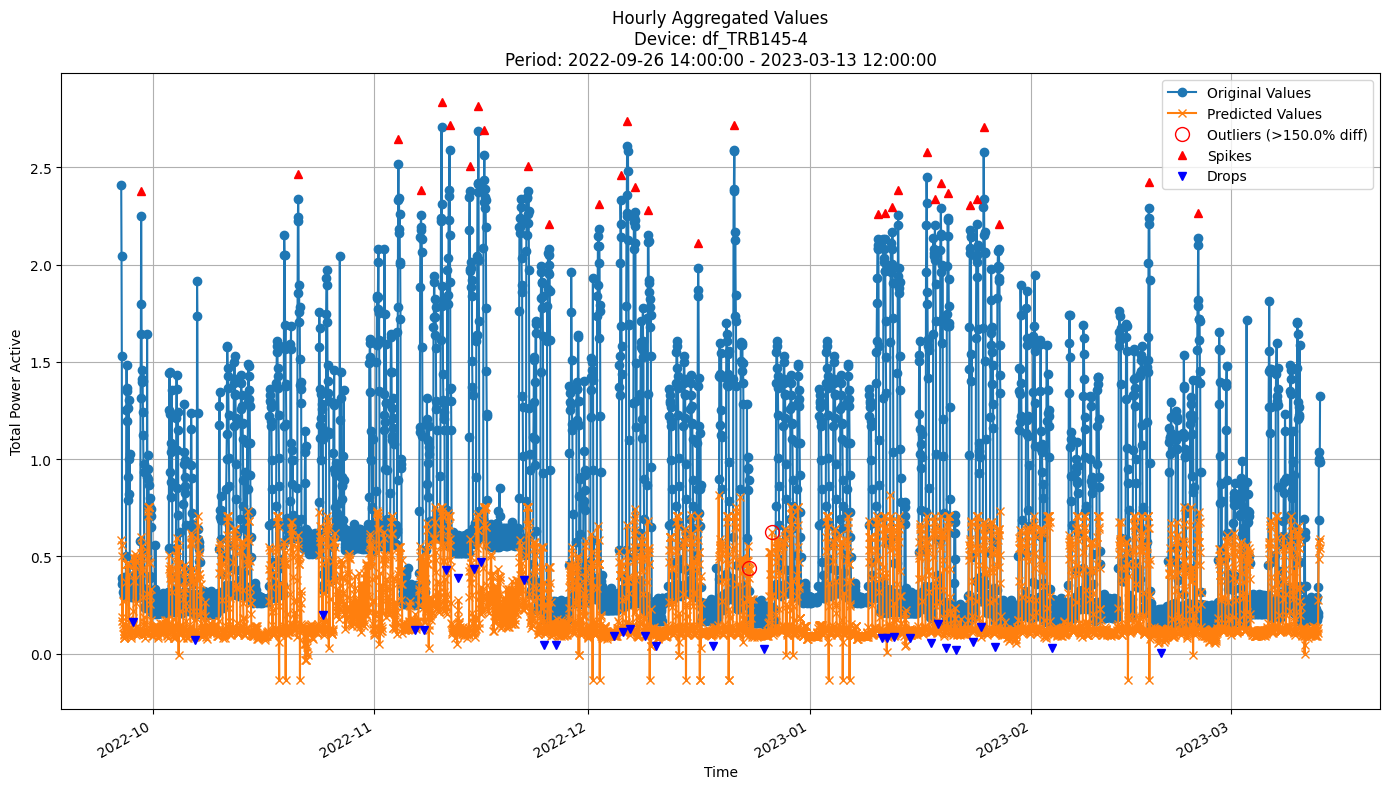


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5923
MAE: 0.4134
MAPE: 56.2010%

Directional Metrics:
Directional Accuracy: 52.4436%
First-Diff Correlation: 0.3331

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0818
  Recall: 0.2812
  F1 Score: 0.1268
Drops:
  Precision: 0.0577
  Recall: 0.1875
  F1 Score: 0.0882

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1364
  Recall: 0.4688
  F1 Score: 0.2113
Drops:
  Precision: 0.0673
  Recall: 0.2188
  F1 Score: 0.1029


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

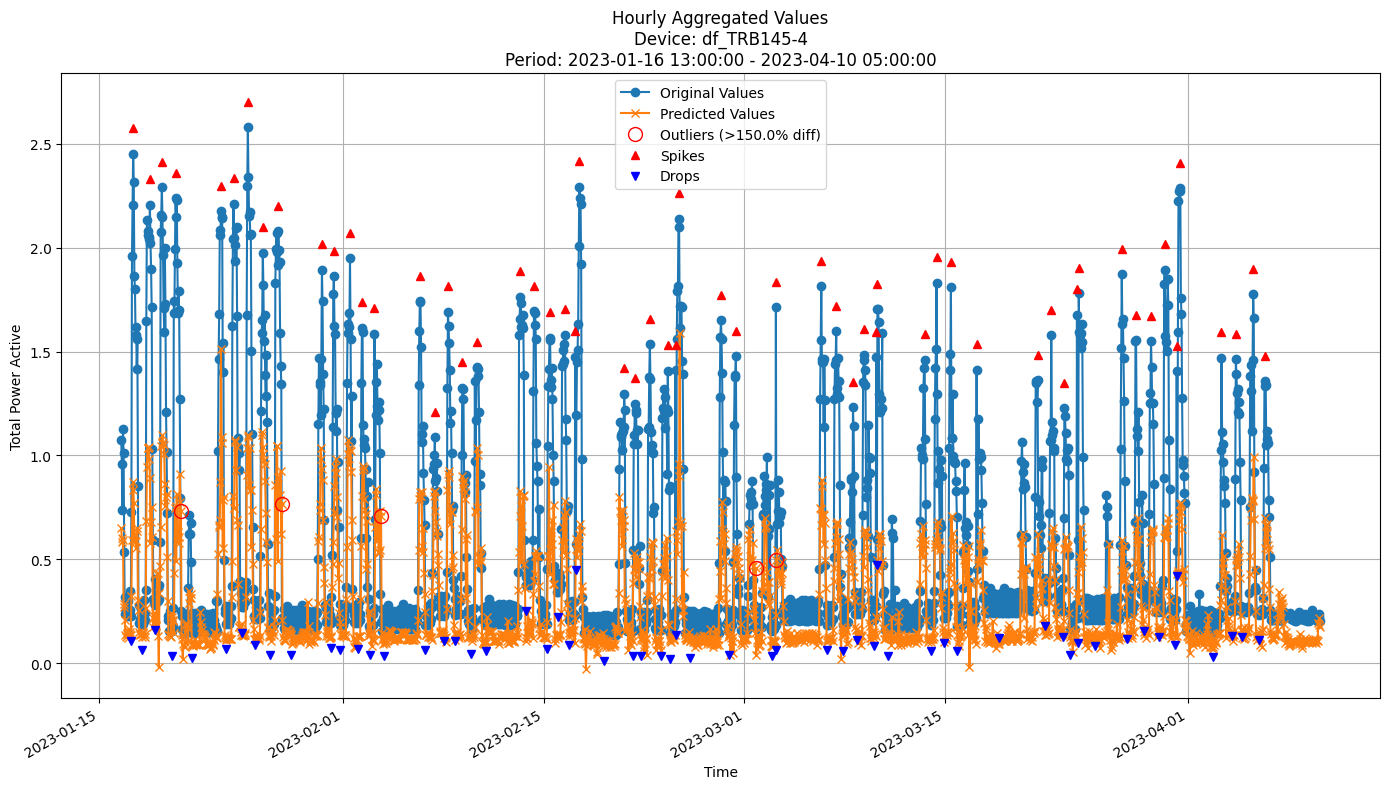


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4418
MAE: 0.2873
MAPE: 46.1003%

Directional Metrics:
Directional Accuracy: 56.4026%
First-Diff Correlation: 0.2913

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.0847
  F1 Score: 0.0840
Drops:
  Precision: 0.1167
  Recall: 0.1186
  F1 Score: 0.1176

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3667
  Recall: 0.3729
  F1 Score: 0.3697
Drops:
  Precision: 0.1667
  Recall: 0.1695
  F1 Score: 0.1681


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [50]:
# Initialize the models and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [bl_prev_params, bl_mean_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf, bl_mean]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "15m"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 15m


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2268
	MAE: 0.0951
	MAPE: 18.9957%

Directional Metrics:
	Directional Accuracy: 9.9959%
	First-Diff Correlation: -0.177

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

Time: 0.02 seconds
Predicting for chunk from 2023-04-10 06:00:00+02:00 to 2023-04-24 06:00:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-04-24 06:00:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-04-24 06:15:00+02:00 to 2023-05-08 06:15:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-05-08 06:15:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-05-08 06:30:00+02:00 to 2023-05-22 06:30:00+02:00

-------------------------

Retraining model on data from 2022-09-26 14:15:00+02:00 to 2023-05-22 06:30:00+02:00

Time: 0.03 seconds
Predicting for chunk from 2023-05-22 06:45:00+02:00 to 2023-05-30 21:30:00+02:00

-------------------------
Model's memory usage: 0.024353 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15min Metrics:

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 1147.812004 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2660
	MAE: 0.1426
	MAPE: 26.3450%

Directional Metrics:
	Directional Accuracy: 50.2262%
	First-Diff Correlation: 0.

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-26 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 18.818810 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4329
	MAE: 0.2769
	MAPE: 49.6381%

Directional Metrics:
	Directional Accuracy: 29.0210%
	First-Diff Correlation: 0.04

In [51]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [52]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [53]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [54]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [55]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n============================15-Min Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "15min")
print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "hourly")


============================15-Min Test Results============================


Device: df_TRB145-4 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.227 ± 0.000,0.095 ± 0.000,18.996 ± 0.000,9.996 ± 0.000,-17.751 ± 0.000,4.211 ± 0.000,31.579 ± 0.000,0.000 ± 0.000,4.301 ± 0.000
1,BL_Mean,0.349 ± 0.000,0.222 ± 0.000,55.598 ± 0.000,13.204 ± 0.000,5.859 ± 0.000,4.651 ± 0.000,11.628 ± 0.000,0.000 ± 0.000,2.381 ± 0.000
2,GBDT,0.212 ± 0.000,0.125 ± 0.000,27.617 ± 0.000,52.345 ± 0.000,19.632 ± 0.000,6.122 ± 0.000,20.408 ± 0.000,4.167 ± 0.000,6.250 ± 0.000
3,RandomForest,0.222 ± 0.000,0.126 ± 0.000,26.098 ± 0.000,54.237 ± 0.000,18.973 ± 0.000,6.742 ± 0.000,15.730 ± 0.000,4.598 ± 0.000,11.494 ± 0.000
4,HoeffdingTree,0.370 ± 0.000,0.213 ± 0.000,42.225 ± 0.000,27.951 ± 0.000,8.680 ± 0.000,3.390 ± 0.000,10.169 ± 0.000,3.125 ± 0.000,6.250 ± 0.000
5,ARF_Hoeffding,0.281 ± 0.000,0.157 ± 0.000,30.099 ± 0.000,47.203 ± 0.000,7.521 ± 0.000,2.151 ± 0.000,6.452 ± 0.000,2.174 ± 0.000,2.174 ± 0.000
6,FastODT,0.346 ± 0.000,0.177 ± 0.000,34.185 ± 0.000,42.596 ± 0.000,0.467 ± 0.000,5.844 ± 0.000,14.286 ± 0.000,1.829 ± 0.000,4.878 ± 0.000
7,ARF_FastODT,0.266 ± 0.000,0.143 ± 0.000,26.345 ± 0.000,50.226 ± 0.000,9.511 ± 0.000,8.000 ± 0.000,18.000 ± 0.000,0.000 ± 0.000,4.082 ± 0.000
8,IncubationBoost,0.433 ± 0.000,0.277 ± 0.000,49.638 ± 0.000,29.021 ± 0.000,4.398 ± 0.000,4.494 ± 0.000,7.865 ± 0.000,0.000 ± 0.000,3.243 ± 0.000




============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.167 ± 0.000,0.076 ± 0.000,13.770 ± 0.000,64.856 ± 0.000,35.648 ± 0.000,17.391 ± 0.000,89.130 ± 0.000,15.556 ± 0.000,37.778 ± 0.000
1,BL_Mean,0.334 ± 0.000,0.212 ± 0.000,52.160 ± 0.000,60.494 ± 0.000,42.136 ± 0.000,19.048 ± 0.000,59.524 ± 0.000,19.512 ± 0.000,31.707 ± 0.000
2,GBDT,0.181 ± 0.000,0.110 ± 0.000,23.814 ± 0.000,60.165 ± 0.000,53.852 ± 0.000,9.756 ± 0.000,63.415 ± 0.000,10.000 ± 0.000,35.000 ± 0.000
3,RandomForest,0.197 ± 0.000,0.111 ± 0.000,22.256 ± 0.000,60.988 ± 0.000,51.779 ± 0.000,9.756 ± 0.000,58.537 ± 0.000,10.000 ± 0.000,27.500 ± 0.000
4,HoeffdingTree,0.339 ± 0.000,0.196 ± 0.000,38.092 ± 0.000,55.720 ± 0.000,33.530 ± 0.000,9.756 ± 0.000,31.707 ± 0.000,22.222 ± 0.000,32.099 ± 0.000
5,ARF_Hoeffding,0.258 ± 0.000,0.145 ± 0.000,26.943 ± 0.000,59.012 ± 0.000,39.683 ± 0.000,12.346 ± 0.000,49.383 ± 0.000,15.190 ± 0.000,22.785 ± 0.000
6,FastODT,0.261 ± 0.000,0.139 ± 0.000,25.926 ± 0.000,55.473 ± 0.000,24.478 ± 0.000,14.000 ± 0.000,44.000 ± 0.000,12.245 ± 0.000,26.531 ± 0.000
7,ARF_FastODT,0.236 ± 0.000,0.125 ± 0.000,21.678 ± 0.000,60.412 ± 0.000,55.004 ± 0.000,27.160 ± 0.000,54.321 ± 0.000,2.532 ± 0.000,20.253 ± 0.000
8,IncubationBoost,0.414 ± 0.000,0.271 ± 0.000,48.287 ± 0.000,55.473 ± 0.000,23.013 ± 0.000,6.818 ± 0.000,29.545 ± 0.000,6.977 ± 0.000,25.581 ± 0.000


## Validation results

In [56]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n============================15-Min Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "15min")
print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "hourly")


============================15-Min Validation Results============================


Device: df_TRB145-4 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.210 ± 0.020,0.107 ± 0.011,21.509 ± 5.029,11.999 ± 0.891,5.281 ± 3.285,7.377 ± 5.332,24.964 ± 8.647,7.293 ± 6.526,16.743 ± 4.947
1,BL_Mean,0.351 ± 0.054,0.252 ± 0.046,58.558 ± 9.937,14.703 ± 1.435,15.615 ± 5.453,5.876 ± 5.067,15.407 ± 8.697,1.709 ± 3.822,4.934 ± 4.949
2,GBDT,0.255 ± 0.040,0.162 ± 0.031,39.161 ± 12.718,54.459 ± 3.823,15.450 ± 7.454,8.267 ± 9.481,15.474 ± 11.982,1.754 ± 3.923,6.866 ± 5.747
3,RandomForest,0.107 ± 0.019,0.066 ± 0.013,12.305 ± 3.165,68.265 ± 1.828,77.001 ± 6.570,15.029 ± 15.363,30.142 ± 33.818,0.660 ± 1.476,0.990 ± 2.214
4,HoeffdingTree,0.378 ± 0.065,0.248 ± 0.050,52.190 ± 7.986,25.692 ± 1.231,5.927 ± 1.670,2.216 ± 3.547,6.197 ± 4.445,1.701 ± 1.707,2.817 ± 3.022
5,ARF_Hoeffding,0.284 ± 0.048,0.187 ± 0.029,40.119 ± 9.662,45.370 ± 1.668,10.481 ± 3.082,2.434 ± 3.842,10.640 ± 8.754,0.877 ± 1.961,3.425 ± 5.796
6,FastODT,0.351 ± 0.039,0.200 ± 0.028,39.020 ± 9.399,34.681 ± 4.096,4.151 ± 3.819,4.881 ± 2.351,10.524 ± 5.695,2.728 ± 2.312,9.045 ± 4.282
7,ARF_FastODT,0.292 ± 0.058,0.195 ± 0.046,45.219 ± 12.475,50.660 ± 2.459,7.587 ± 2.458,4.790 ± 5.297,18.105 ± 8.983,1.658 ± 2.359,3.482 ± 2.506
8,IncubationBoost,0.496 ± 0.061,0.336 ± 0.057,47.435 ± 1.137,23.521 ± 4.777,5.649 ± 3.418,1.709 ± 3.822,8.029 ± 7.209,0.529 ± 1.183,4.736 ± 2.666




============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.183 ± 0.019,0.101 ± 0.011,19.720 ± 4.474,58.506 ± 4.185,45.443 ± 5.512,23.374 ± 5.805,75.481 ± 7.262,11.197 ± 4.742,45.131 ± 7.223
1,BL_Mean,0.335 ± 0.054,0.242 ± 0.047,53.821 ± 8.073,63.404 ± 6.387,59.548 ± 12.612,27.455 ± 12.960,57.182 ± 11.077,15.308 ± 12.120,22.883 ± 10.854
2,GBDT,0.226 ± 0.040,0.146 ± 0.029,34.332 ± 11.402,62.051 ± 5.608,45.884 ± 15.139,17.180 ± 14.685,59.921 ± 15.853,15.312 ± 7.641,25.098 ± 7.075
3,RandomForest,0.086 ± 0.018,0.052 ± 0.011,9.192 ± 2.428,82.210 ± 3.198,89.853 ± 3.551,26.915 ± 32.851,29.108 ± 35.037,6.955 ± 10.795,7.832 ± 11.457
4,HoeffdingTree,0.343 ± 0.067,0.228 ± 0.050,46.410 ± 6.984,55.715 ± 2.608,32.229 ± 9.256,9.335 ± 7.281,23.741 ± 14.550,4.965 ± 5.003,10.665 ± 8.203
5,ARF_Hoeffding,0.261 ± 0.049,0.173 ± 0.029,35.563 ± 8.046,56.652 ± 5.792,44.939 ± 13.041,13.425 ± 6.425,43.579 ± 14.479,5.135 ± 7.731,19.722 ± 11.018
6,FastODT,0.277 ± 0.033,0.166 ± 0.024,31.325 ± 7.151,56.209 ± 3.669,29.155 ± 12.471,12.138 ± 7.442,37.472 ± 6.033,8.036 ± 8.306,24.347 ± 12.465
7,ARF_FastODT,0.262 ± 0.053,0.177 ± 0.045,39.595 ± 11.623,57.093 ± 3.146,45.371 ± 8.948,22.740 ± 10.622,48.062 ± 24.894,12.064 ± 13.749,24.696 ± 15.246
8,IncubationBoost,0.482 ± 0.061,0.331 ± 0.058,46.573 ± 1.525,56.125 ± 4.433,30.013 ± 12.295,7.126 ± 4.853,29.496 ± 10.169,7.289 ± 6.572,14.463 ± 6.375


### By-period validation results

In [57]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (**higher is better**)


In [58]:
print("\n\n=============================15-Min Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="dir_accuracy",
    display_gain=True
)
print("\n\n\n=============================Hourly Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)



=============================15-Min Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,11.277,14.254,53.405,52.661,25.679,42.761,36.211,48.344,15.668,33.362222
Period 2,12.393,14.254,55.080,56.345,25.902,45.999,35.020,48.418,22.181,35.065778
Period 3,13.547,17.752,62.560,60.514,23.372,45.813,28.024,55.489,20.878,36.438778
Period 4,11.984,14.849,52.661,55.750,26.610,48.195,30.927,51.842,24.153,35.219000
Period 5,12.095,13.509,51.768,51.396,25.270,45.218,37.663,50.167,27.838,34.991556
Period 6,10.701,13.602,51.281,51.356,27.317,44.235,40.241,49.699,30.407,35.426556



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,1.116,0.000,1.675,3.684,0.223,3.238,-1.191,0.074,6.513,1.704
Period 3 - Period 2,1.154,3.498,7.480,4.169,-2.530,-0.186,-6.996,7.071,-1.303,1.373
Period 4 - Period 3,-1.563,-2.903,-9.899,-4.764,3.238,2.382,2.903,-3.647,3.275,-1.220
Period 5 - Period 4,0.111,-1.340,-0.893,-4.354,-1.340,-2.977,6.736,-1.675,3.685,-0.227
Period 6 - Period 5,-1.394,0.093,-0.487,-0.040,2.047,-0.983,2.578,-0.468,2.569,0.435





=============================Hourly Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,53.949,66.170,62.295,59.016,55.887,55.589,58.271,52.906,49.627,57.078889
Period 2,60.358,60.358,60.209,62.891,58.271,62.891,59.613,56.781,55.440,59.645778
Period 3,66.766,75.857,70.343,69.449,59.016,63.934,59.463,63.338,62.295,65.606778
Period 4,57.675,63.189,66.021,62.742,55.291,58.271,57.228,57.079,51.714,58.801111
Period 5,56.781,56.632,61.401,57.526,54.844,51.416,53.055,55.440,60.060,56.350556
Period 6,55.505,58.220,52.036,47.813,50.980,47.813,49.623,57.014,57.617,52.957889



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.409,-5.812,-2.086,3.875,2.384,7.302,1.342,3.875,5.813,2.567
Period 3 - Period 2,6.408,15.499,10.134,6.558,0.745,1.043,-0.150,6.557,6.855,5.961
Period 4 - Period 3,-9.091,-12.668,-4.322,-6.707,-3.725,-5.663,-2.235,-6.259,-10.581,-6.806
Period 5 - Period 4,-0.894,-6.557,-4.620,-5.216,-0.447,-6.855,-4.173,-1.639,8.346,-2.451
Period 6 - Period 5,-1.276,1.588,-9.365,-9.713,-3.864,-3.603,-3.432,1.574,-2.443,-3.393


#### MAPE (**lower is better**)

In [59]:
print("\n\n=============================15-Min MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="mape",
    display_gain=True
)
print("\n\n\n=============================Hourly MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)



=============================15-Min MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,13.912,38.101,21.437,22.408,41.736,24.057,25.164,35.559,48.143,30.057444
Period 2,21.898,63.320,39.205,36.792,63.345,45.025,44.485,66.038,47.250,47.484222
Period 3,16.668,57.096,28.615,27.570,41.744,31.627,26.819,29.541,47.915,34.177222
Period 4,26.352,66.050,60.662,43.315,55.023,48.223,45.343,54.102,45.088,49.350889
Period 5,28.354,68.203,48.011,41.941,57.631,51.959,49.119,49.067,47.566,49.094556
Period 6,21.871,58.577,37.037,35.066,53.662,39.823,43.192,37.005,48.645,41.653111



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,7.986,25.219,17.768,14.384,21.609,20.968,19.321,30.479,-0.893,17.427
Period 3 - Period 2,-5.230,-6.224,-10.590,-9.222,-21.601,-13.398,-17.666,-36.497,0.665,-13.307
Period 4 - Period 3,9.684,8.954,32.047,15.745,13.279,16.596,18.524,24.561,-2.827,15.174
Period 5 - Period 4,2.002,2.153,-12.651,-1.374,2.608,3.736,3.776,-5.035,2.478,-0.256
Period 6 - Period 5,-6.483,-9.626,-10.974,-6.875,-3.969,-12.136,-5.927,-12.062,1.079,-7.441





=============================Hourly MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,13.151,37.004,18.691,20.236,38.432,22.488,21.406,31.940,47.989,27.926333
Period 2,19.894,58.459,33.927,32.011,57.617,40.626,36.243,60.446,46.136,42.817667
Period 3,15.343,53.202,25.266,23.847,37.092,28.026,21.695,25.192,46.985,30.738667
Period 4,23.697,59.537,54.200,37.077,47.556,41.681,37.235,46.344,43.571,43.433111
Period 5,26.186,61.143,41.673,34.683,50.116,45.431,38.729,41.768,46.576,42.922778
Period 6,20.052,53.582,32.234,30.799,47.647,35.128,32.644,31.883,48.180,36.905444



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.743,21.455,15.236,11.775,19.185,18.138,14.837,28.506,-1.853,14.891
Period 3 - Period 2,-4.551,-5.257,-8.661,-8.164,-20.525,-12.600,-14.548,-35.254,0.849,-12.079
Period 4 - Period 3,8.354,6.335,28.934,13.230,10.464,13.655,15.540,21.152,-3.414,12.694
Period 5 - Period 4,2.489,1.606,-12.527,-2.394,2.560,3.750,1.494,-4.576,3.005,-0.510
Period 6 - Period 5,-6.134,-7.561,-9.439,-3.884,-2.469,-10.303,-6.085,-9.885,1.604,-6.017


#### RMSE (**lower is better**)

In [60]:
print("\n\n=============================15-Min RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="rmse",
    display_gain=True
)
print("\n\n\n=============================Hourly RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)



=============================15-Min RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15min | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.218,0.465,0.312,0.310,0.510,0.371,0.375,0.379,0.605,0.393889
Period 2,0.232,0.366,0.266,0.258,0.404,0.294,0.372,0.355,0.535,0.342444
Period 3,0.171,0.313,0.192,0.184,0.315,0.212,0.269,0.212,0.474,0.260222
Period 4,0.228,0.317,0.291,0.267,0.352,0.291,0.349,0.284,0.500,0.319889
Period 5,0.212,0.315,0.231,0.232,0.330,0.284,0.390,0.275,0.444,0.301444
Period 6,0.199,0.329,0.235,0.230,0.356,0.255,0.349,0.248,0.421,0.291333



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.014,-0.099,-0.046,-0.052,-0.106,-0.077,-0.003,-0.024,-0.070,-0.051
Period 3 - Period 2,-0.061,-0.053,-0.074,-0.074,-0.089,-0.082,-0.103,-0.143,-0.061,-0.082
Period 4 - Period 3,0.057,0.004,0.099,0.083,0.037,0.079,0.080,0.072,0.026,0.060
Period 5 - Period 4,-0.016,-0.002,-0.060,-0.035,-0.022,-0.007,0.041,-0.009,-0.056,-0.018
Period 6 - Period 5,-0.013,0.014,0.004,-0.002,0.026,-0.029,-0.041,-0.027,-0.023,-0.010





=============================Hourly RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.185,0.450,0.282,0.286,0.481,0.351,0.309,0.336,0.591,0.363444
Period 2,0.203,0.348,0.231,0.229,0.370,0.266,0.278,0.325,0.518,0.307556
Period 3,0.149,0.302,0.168,0.165,0.287,0.190,0.219,0.187,0.465,0.236889
Period 4,0.203,0.300,0.269,0.246,0.315,0.270,0.291,0.261,0.487,0.293556
Period 5,0.185,0.298,0.202,0.208,0.292,0.260,0.313,0.247,0.429,0.270444
Period 6,0.171,0.313,0.201,0.201,0.312,0.229,0.252,0.218,0.405,0.255778



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.018,-0.102,-0.051,-0.057,-0.111,-0.085,-0.031,-0.011,-0.073,-0.056
Period 3 - Period 2,-0.054,-0.046,-0.063,-0.064,-0.083,-0.076,-0.059,-0.138,-0.053,-0.071
Period 4 - Period 3,0.054,-0.002,0.101,0.081,0.028,0.080,0.072,0.074,0.022,0.057
Period 5 - Period 4,-0.018,-0.002,-0.067,-0.038,-0.023,-0.010,0.022,-0.014,-0.058,-0.023
Period 6 - Period 5,-0.014,0.015,-0.001,-0.007,0.020,-0.031,-0.061,-0.029,-0.024,-0.015
